In [ ]:

import torch
import pandas as pd
import os,sys
from PIL import Image
device = torch.device('cuda:0')
import time
from torch import nn, cuda, device
from torch.autograd import Variable
import torchvision
from torch.utils.data import Dataset# data management
import numpy as np
import torch.optim as optim # Optimization algorithm
import matplotlib.pyplot as plt
import torchvision as tv
import itertools
import pickle
from tqdm import tqdm
import torchvision.transforms as transforms
import random
from scipy.spatial.distance import cdist
from torchvision.utils import save_image
print(cuda.is_available())
device = device('cuda:0')
print(device)
import sys
import scipy.stats as stats
import glob
import numpy as np
import pickle
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.colorbar as mplCB
import cv2 as cv2
import pandas as pd
import matplotlib as mpl
import math
from numpy.linalg import norm 
import yaml
from skimage.morphology import extrema
from skimage.color import rgb2hed
from scipy import ndimage
os.chdir('./code')
from function_define import *

True
cuda:0
True
cuda:0


In [ ]:
yaml_paths = './data/data_dir.yaml'
with open(yaml_paths, 'r') as yaml_file:
    file_paths = yaml.safe_load(yaml_file)
    
save_dir = file_paths['real_data']['real_data_4000patches']
with open(save_dir,'rb') as f:
  real_data = pickle.load(f)
  
save_dir = file_paths['real_data']['real_data_120000patches']
with open(save_dir,'rb') as f:
  data = pickle.load(f)
  
save_dir = file_paths['synthetic_data']['synthetic_data_grade1to4']
with open(save_dir,'rb') as f:
    traverse_data = pickle.load(f)
  
save_dir = file_paths['HoverNet_mask']
with open(save_dir, 'rb') as f:
    hovernet_testing = pickle.load(f)
save_dir = file_paths['ViT_explanation']
with open(save_dir, 'rb') as f:
    vit_explain = pickle.load(f)

/project/bioinformatics/Rajaram_lab/shared/Environment/Conda/Thuongenv/lib/python3.9/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/project/bioinformatics/Rajaram_lab/shared/Environment/Conda/Thuongenv/lib/python3.9/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG19_Weights.IMAGENET1K_V1`. You can also use `weights=VGG19_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


100%|██████████| 16/16 [00:09<00:00,  1.77it/s]


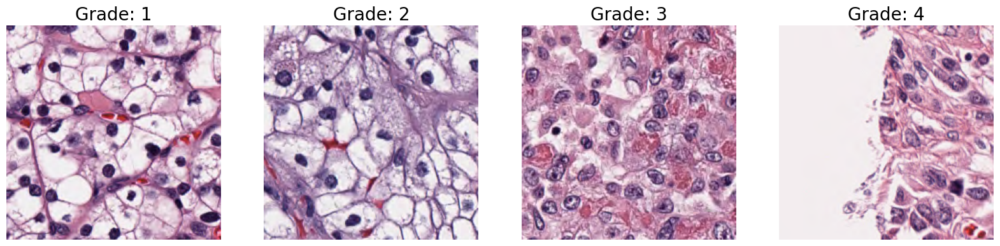

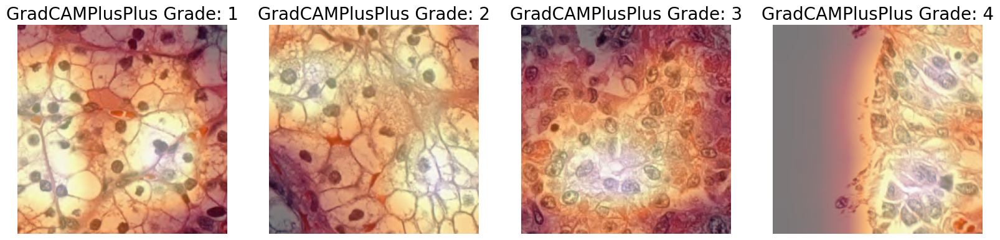

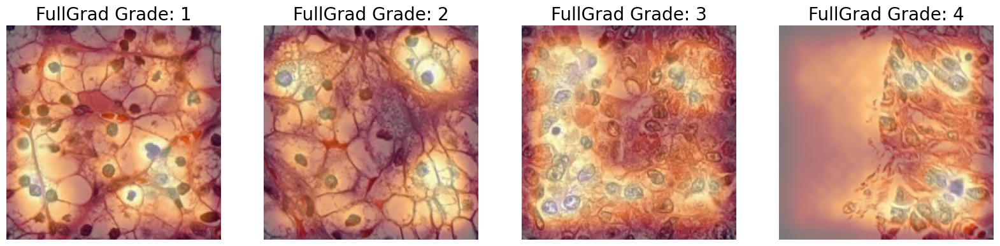

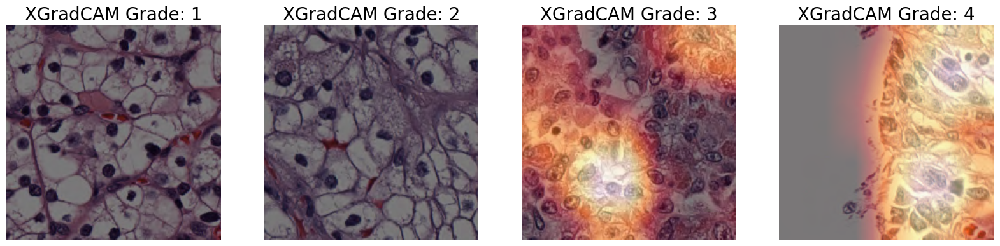

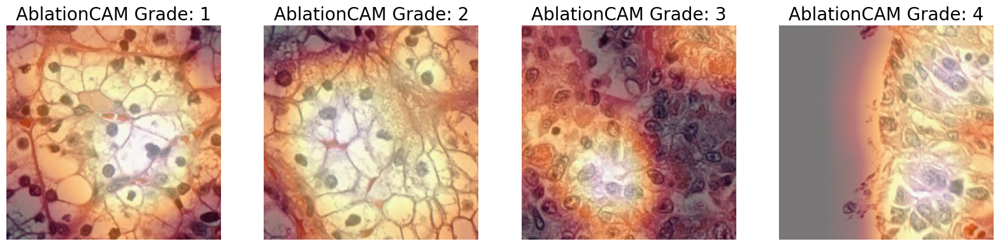

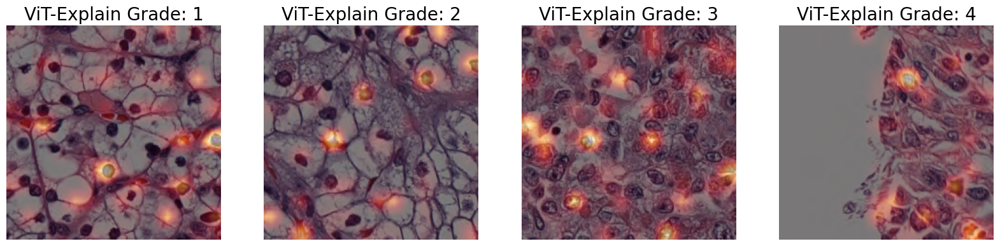

In [ ]:
#%% plot gradcam for real data from pretrained VGG19 model
from pytorch_grad_cam import GradCAM, ScoreCAM, GradCAMPlusPlus, AblationCAM, XGradCAM, EigenCAM, FullGrad
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
save_dir = file_paths['real_data']['real_data_4000patches']
with open(save_dir,'rb') as f:
  real_data = pickle.load(f)

import torchvision.models as models

save_path = file_paths['WEIGHTS']['grade_classifier']
num_classes = 4
num_epochs = 50
learning_rate = 1e-4

model = models.vgg19(pretrained= True)
model.classifier[6] = nn.Linear(in_features = 4096, out_features = num_classes, bias=True)
model.load_state_dict(torch.load(save_path))
model.eval()

target_layers =  [model.features[-1]]

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
cam = GradCAMPlusPlus(model=model, target_layers=target_layers) 

idx_list = []
img_list = []
gradcam_img_list = []
for grd in range(4):
  idx = np.where(data['classes'][real_data['idx']] == grd)[0]
  target_category = [ClassifierOutputTarget(grd)]
  np.random.shuffle(idx)
  idx = idx[0]
  idx_list.append(idx)
  img = real_data['img'][idx]
  img = Image.fromarray(img)
  img = transform(img).unsqueeze(0)
  img_list.append(img)
  gradcam_img = cam(input_tensor=img, targets=target_category)
  gradcam_img = gradcam_img.squeeze()
  gradcam_img_list.append(gradcam_img)

plt.figure(figsize=(20,5))
for i in range(4):
  plt.subplot(1,4,i+1)
  plt.imshow(real_data['img'][idx_list[i]])
  plt.title('Grade: {}'.format(i+1), fontsize = 20)
  plt.axis('off') 
  
# plt.figure(figsize=(20,5))
# for i in range(4):
#   plt.subplot(1,4,i+1)
#   plt.imshow(real_data['img'][idx_list[i]])
#   plt.imshow(gradcam_img_list[i], cmap='afmhot', alpha=0.5)
#   plt.title('Gradcampp Grade: {}'.format(i+1), fontsize = 20)
#   plt.axis('off')  

gradcam_img_list = []
gradcam_models_list = [GradCAMPlusPlus, FullGrad, XGradCAM,  AblationCAM]
gradcam_models_name_list = ['GradCAMPlusPlus', 'FullGrad', 'XGradCAM', 'AblationCAM']
for i in range(len(gradcam_models_list)):
  cam = gradcam_models_list[i](model=model, target_layers=target_layers) 
  cam_name = gradcam_models_name_list[i]
  gradcam_img_list = []
  for grd in range(4):
    idx = idx_list[grd]
    img = real_data['img'][idx]
    img = Image.fromarray(img)
    img = transform(img).unsqueeze(0)
    img_list.append(img)
    gradcam_img = cam(input_tensor=img, targets=target_category)
    gradcam_img = gradcam_img.squeeze()
    gradcam_img_list.append(gradcam_img)
  
  plt.figure(figsize=(20,5))
  for i in range(4):
    plt.subplot(1,4,i+1)
    plt.imshow(real_data['img'][idx_list[i]])
    plt.imshow(gradcam_img_list[i], cmap='afmhot', alpha=0.5)
    plt.title(cam_name +' Grade: {}'.format(i+1), fontsize = 20)
    plt.axis('off')  

plt.figure(figsize=(20,5))
for i in range(4):
    plt.subplot(1,4,i+1)
    plt.imshow(real_data['img'][idx_list[i]])
    plt.imshow(vit_explain['ViT_explain'][idx_list[i]], cmap='afmhot', alpha=0.5)
    plt.title('ViT-Explain' +' Grade: {}'.format(i+1), fontsize = 20)
    plt.axis('off')  

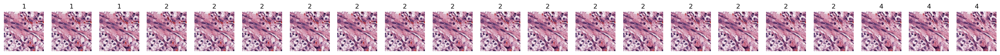

In [15]:
plt.figure(figsize=(33,3))
idx = np.random.randint(0,len(traverse_data['img']))
for i in range(traverse_data['img'][0].shape[0]):
    plt.subplot(1,traverse_data['img'][idx].shape[0],i+1)
    plt.imshow(traverse_data['img'][idx][i])
    plt.title(traverse_data['class'][idx][i]+1)
    plt.axis('off')


/project/shared/kapur_rajaram_no_phi/Publications/202112_CancerResearch_BAP1/Final_Data/Patch_Data/WSI/


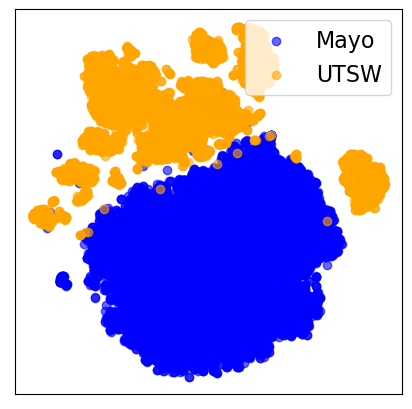

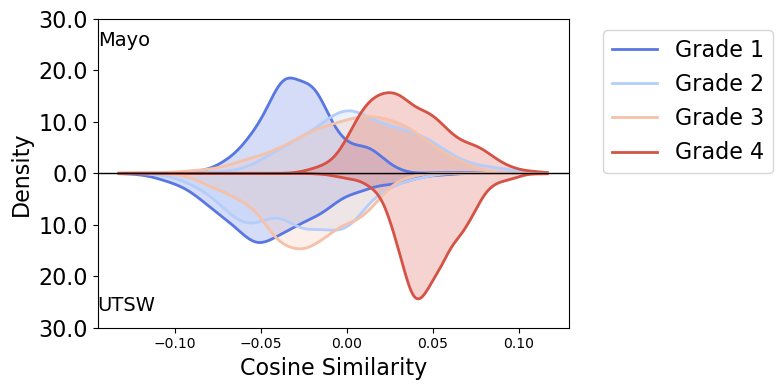

In [ ]:
mayo_data = file_paths['original_dir']['BAP1']['data_dir']
print(mayo_data)
mayo_file_list = os.listdir(mayo_data)
mayo_file_list = [f.split('.')[0] for f in mayo_file_list]
mayo_grade_idx = []
utsw_grade_idx = []
for i in range(traverse_data['full_grade_list'].shape[0]):
    if data['patients'][traverse_data['idx'][i]] in mayo_file_list:
        mayo_grade_idx.append(i)
    else:
        utsw_grade_idx.append(i)
save_dir = './DIFFAE_grade/datasets/training_data_18k_alldata.pkl'
with open(save_dir,'rb') as f:
  DIFFAE_train_data = pickle.load(f)
mayo_DIFFAE_grade_list = []
utsw_DIFFAE_grade_list = []
for i in range(8000):
    if DIFFAE_train_data['patients'][i] in mayo_file_list:
        mayo_DIFFAE_grade_list.append(i)
    else:        
        utsw_DIFFAE_grade_list.append(i)

mayo_DIFFAE_grade_list = np.array(mayo_DIFFAE_grade_list)
utsw_DIFFAE_grade_list = np.array(utsw_DIFFAE_grade_list)
feature = DIFFAE_train_data['feature']
mean = np.mean(feature, axis=0)
std = np.std(feature, axis=0)
norm_feature = (feature - mean) / std
#show tsne plot of the Mayo data and UTSW data 
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
# Combine Mayo and UTSW data for t-SNE
combined_data = np.concatenate((norm_feature[mayo_DIFFAE_grade_list], norm_feature[utsw_DIFFAE_grade_list]), axis=0)
mayo_labels = np.array(['Mayo'] * len(mayo_DIFFAE_grade_list))
utsw_labels = np.array(['UTSW'] * len(utsw_DIFFAE_grade_list))
mayo_grade_labels = data['classes'][DIFFAE_train_data['idx'][mayo_DIFFAE_grade_list]]
utsw_grade_labels = data['classes'][DIFFAE_train_data['idx'][utsw_DIFFAE_grade_list]]
combined_labels = np.concatenate((mayo_labels, utsw_labels), axis=0)
# Perform t-SNE
# combined_labels = np.concatenate((mayo_labels, utsw_labels, unknown_labels), axis=0)
norm_feature = (feature - mean) / std
label_list = []
for i in range(len(DIFFAE_train_data['idx'])):
    if i in mayo_DIFFAE_grade_list:
        label_list.append('Mayo')
    elif i in utsw_DIFFAE_grade_list:
        label_list.append('UTSW')
label_list = np.concatenate([label_list, ['Mayo']*10000])
tsne = TSNE(n_components=2, random_state=42)
tsne_results = tsne.fit_transform(norm_feature)
# Plot t-SNE results
plt.figure(figsize=(5, 5))
unique_labels = np.unique(label_list)
colors = {'Mayo': 'blue', 'UTSW': 'orange'}
for i, label in enumerate(unique_labels):
    indices = np.where(label_list == label)
    plt.scatter(tsne_results[indices, 0], tsne_results[indices, 1], color=colors[label], label=label, alpha=0.6)
plt.legend(fontsize=16)
plt.xticks([])
plt.yticks([])
# plt.title('t-SNE of Mayo and UTSW Data', fontsize=16)
# plt.xlabel('t-SNE Dimension 1', fontsize=14)
# plt.ylabel('t-SNE Dimension 2', fontsize=14)
# plt.grid(True, linestyle='--', alpha=0.5)
# plt.tight_layout()
plt.show()
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

plt.figure(figsize=(8, 4))
linear_cls_weight = np.load(file_paths['WEIGHTS']['cls_DIFFAE_vec'])
#projection of the Mayo data and UTSW data on the linear classifier weight
mayo_projection = np.divide(np.dot(norm_feature[mayo_DIFFAE_grade_list], linear_cls_weight[3]), np.linalg.norm(linear_cls_weight[3])*norm(norm_feature[mayo_DIFFAE_grade_list], axis=1))
utsw_projection = np.divide(np.dot(norm_feature[utsw_DIFFAE_grade_list], linear_cls_weight[3]), np.linalg.norm(linear_cls_weight[3])*norm(norm_feature[utsw_DIFFAE_grade_list], axis=1))
# choose a diverging colormap
cmap = plt.cm.coolwarm
colors = cmap(np.linspace(0.1, 0.9, 4))   # 4 colors for Grade 1-4

# common x-range across both datasets
all_values = np.concatenate([mayo_projection, utsw_projection])
x_range = np.linspace(np.min(all_values), np.max(all_values), 300)

# Mayo on top
for grade in range(4):
    grade_projection = mayo_projection[
        data['classes'][DIFFAE_train_data['idx'][mayo_DIFFAE_grade_list]] == grade
    ]
    kde = gaussian_kde(grade_projection)
    y = kde(x_range)

    plt.plot(x_range, y, color=colors[grade], linewidth=2, label=f'Grade {grade+1}')
    plt.fill_between(x_range, 0, y, color=colors[grade], alpha=0.25)

# UTSW on bottom
for grade in range(4):
    grade_projection = utsw_projection[
        data['classes'][DIFFAE_train_data['idx'][utsw_DIFFAE_grade_list]] == grade
    ]
    kde = gaussian_kde(grade_projection)
    y = kde(x_range)

    plt.plot(x_range, -y, color=colors[grade], linewidth=2)
    plt.fill_between(x_range, 0, -y, color=colors[grade], alpha=0.25)

# center line
plt.axhline(0, color='black', linewidth=1)

# axis labels and title
plt.xlabel('Cosine Similarity', fontsize=16)
plt.ylabel('Density', fontsize=16)
# plt.title('Projection Density: Mayo (top) vs UTSW (bottom)', fontsize=16)

# optional: show positive values on both sides of y-axis
yticks = plt.yticks()[0]
plt.yticks(yticks, [f'{abs(y):.1f}' for y in yticks], fontsize=16)

# dataset labels
ymin, ymax = plt.ylim()
xmin, xmax = plt.xlim()
plt.text(xmin, ymax * 0.92, 'Mayo', fontsize=14, va='top')
plt.text(xmin, ymin * 0.92, 'UTSW', fontsize=14, va='bottom')

plt.legend(fontsize=16, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

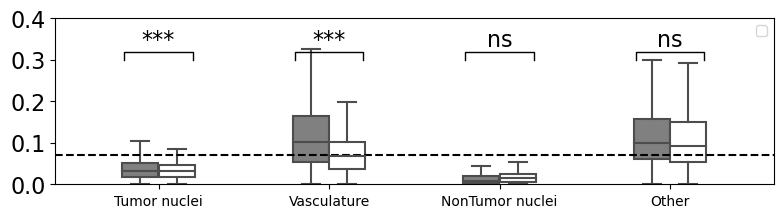

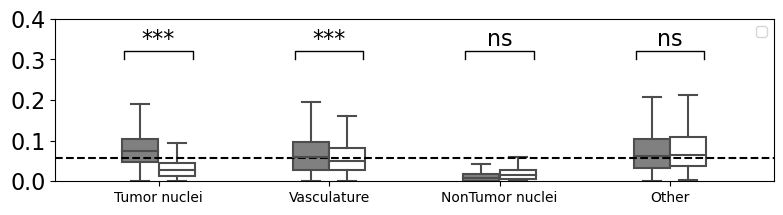

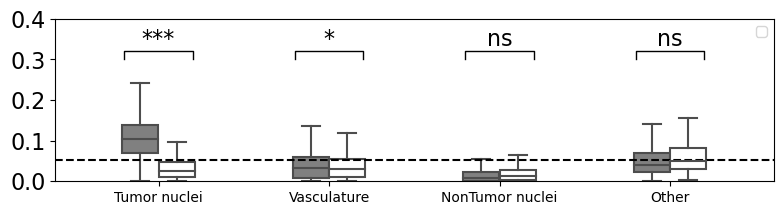

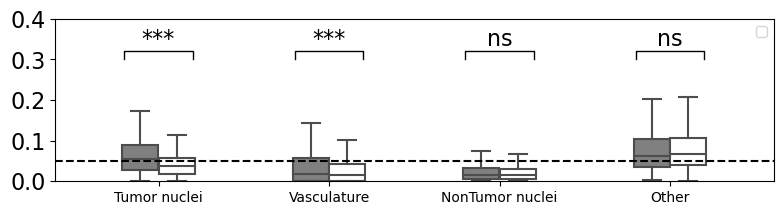

/tmp/ipykernel_323551/1552504117.py:205: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_means = df.groupby(['A', 'B'])['C'].mean().reset_index()
/tmp/ipykernel_323551/1552504117.py:206: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_std = df.groupby(['A', 'B'])['C'].std().reset_index()


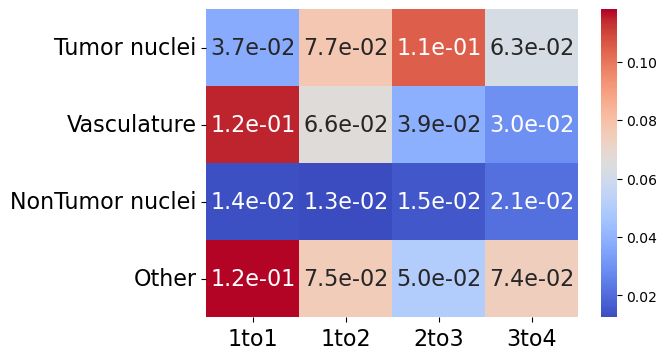

100%|██████████| 977/977 [00:04<00:00, 206.75it/s]
/tmp/ipykernel_323551/1552504117.py:317: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_means = df.groupby(['A', 'B']).C.median().reset_index()
/tmp/ipykernel_323551/1552504117.py:318: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_std= df.groupby(['A', 'B']).C.std().reset_index()


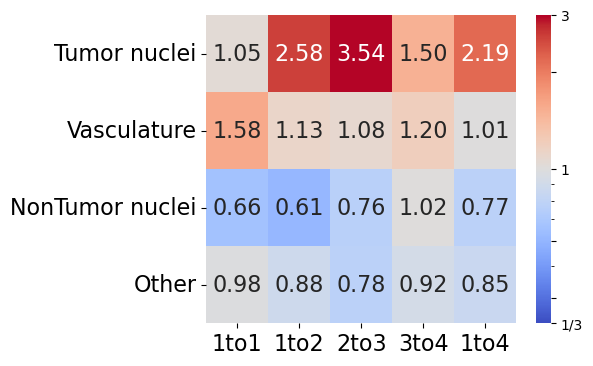

In [ ]:
# Compute Jaccard rate for each component
start_grd = 0
# start_grd = 3
components = ['Tumor nuclei', 'Vasculature',  'NonTumor nuclei','Other']
cohort =  'All' #['Mayo', 'UTSW', 'All']

heatmap_type_list = ['same_grade', 'full_grade'] #['Gradcampp_mask', 'ViT_explain']
data_real_syn = 'Syn'
mask_type = 'NucSeg' #['Hovernet', 'NucSeg']
jaccard_index_alldummytype_list = []
Component_alldummytype_list = []
grade_alldummytype_list = []
dummytype_alldummytype_list = []
presence_alldummytype_list = []
pivot_table_list = []
if data_real_syn == 'Syn':
    start_grd = 0
    save_dir = file_paths['synthetic_data']['synthetic_data_grade1to4']
    # start_grd = 3
    # save_dir = file_paths['synthetic_data']['synthetic_data_grade4to1']
    with open(save_dir,'rb') as f:
        observed_data = pickle.load(f)
    # shuffle_idx = np.arange(observed_data['full_grade_list'].shape[0])
    # np.random.shuffle(shuffle_idx)
    # observed_data['dummy_list'] = shuffle_idx
    if cohort == 'UTSW':
        chosen_idx = utsw_grade_idx
        dummy_list_name =  'utsw_shuffle_idx'
    elif cohort == 'Mayo':
        chosen_idx = mayo_grade_idx
        dummy_list_name =  'mayo_shuffle_idx'
    else:
        chosen_idx = np.arange(len(observed_data['full_grade_list_vas']))
        dummy_list_name =  'dummy_list'
    observed_data['full_grade_list_vas'] = observed_data['full_grade_list_vas'][chosen_idx]
    observed_data['full_grade_list_Nuc_seg'] = observed_data['full_grade_list_Nuc_seg'][chosen_idx]
    observed_data['patient_across_img_Nuc_seg'] = observed_data['patient_across_img_Nuc_seg'][chosen_idx]
    # observed_data['dummy_list'] = np.random.permutation(np.arange(len(observed_data['full_grade_list_vas'])))
    observed_data['dummy_list'] = observed_data[dummy_list_name]
    observed_data['mean_abs_transform_AAEfilter09_patient_across'] = observed_data['mean_abs_transform_AAEfilter09_patient_across'][chosen_idx]
    observed_data['mean_abs_transform_AAEfilter09_grade_across'] = observed_data['mean_abs_transform_AAEfilter09_grade_across'][chosen_idx]
    observed_data['mean_abs_transform_AAEfilter09_grade_across_jump'] = observed_data['mean_abs_transform_AAEfilter09_grade_across_jump'][chosen_idx]
    if mask_type == 'Hovernet':
        observed_data['full_grade_list_Nuc_seg'] = hovernet_testing['full_grade_list_HoverNet_Nucseg_converted3class']
        observed_data['patient_across_img_Nuc_seg'] = hovernet_testing['full_grade_list_HoverNet_Nucseg_patient_across_converted3class']
else: 
    observed_data = {}
    observed_data['full_grade_list_vas'] = []
    observed_data['full_grade_list_Nuc_seg'] = []
    observed_data['full_grade_list_gradcam'] = {'Gradcampp_mask': []}
    for grade in range(4):
        idx = np.where(data['classes'][real_data['idx']] == grade)[0]
        observed_data['full_grade_list_vas'].append(real_data['vas'][idx])
        observed_data['full_grade_list_Nuc_seg'].append(real_data['Nuc_Seg'][idx])
        if 'GradCam_mask' in heatmap_type_list:
            observed_data['full_grade_list_gradcam']['Gradcampp_mask'].append(real_data['Gradcam']['Gradcampp_mask'][idx])
        else:
            observed_data['full_grade_list_gradcam']['Gradcampp_mask'].append(vit_explain['ViT_explain'][idx])
    observed_data['full_grade_list_vas'] = np.stack(observed_data['full_grade_list_vas'], axis=0).transpose(1,0,2,3)
    observed_data['full_grade_list_Nuc_seg'] = np.stack(observed_data['full_grade_list_Nuc_seg'], axis=0).transpose(1,0,2,3)
    observed_data['full_grade_list_gradcam']['Gradcampp_mask'] = np.stack(observed_data['full_grade_list_gradcam']['Gradcampp_mask'], axis=0).transpose(1,0,2,3)
    observed_data['dummy_list'] = real_data['dummy_list']
dummy_list = [0,1]
for heatmap_type in heatmap_type_list:

    idx_sample = np.arange(observed_data['full_grade_list_Nuc_seg'].shape[0])
    # idx_sample = utsw_grade_idx
    # idx_sample = np.arange(traverse_data['mean_abs_transform_clsfilter23_patient_across'].shape[0])
    jaccard_index_list = []
    Component_list = []
    grade_list = []
    dummytype_list = []
    presence_list = []
    # Processing samples and calculating heatmaps
    for dummy in dummy_list:
    
        idx_grade_list = start_grd
        if heatmap_type == 'same_grade':
            heatmap_array = observed_data['mean_abs_transform_AAEfilter09_patient_across'][idx_sample,None,:,:]
            # heatmap_array = observed_data['mean_abs_transform_clsfilter13_patient_across'][:,None,:,:]
        elif heatmap_type == 'full_grade':
            heatmap_array = observed_data['mean_abs_transform_AAEfilter09_grade_across'][idx_sample]
            # heatmap_array = observed_data['mean_abs_transform_clsfilter13_grade_across'][idx_sample]
        elif heatmap_type == 'GradCam_mask':
            gradcam_model = 'Gradcampp_mask' #'AblationCAM_mask', 'Gradcam_mask', 'Gradcampp_mask
            heatmap_array = observed_data['full_grade_list_gradcam'][gradcam_model][idx_sample]
            idx_grade_list = np.concatenate([0, 1, 2, 3]*len(idx_sample), axis=None)
        observed_masks = process_masks(observed_data, start_grd, idx_sample, heatmap_type)
        heatmap_list, component_name, grade, presence = process_samples(
            len(idx_sample),
            heatmap_array,
            observed_masks, observed_data['dummy_list'][idx_sample], dummy, idx_grade_list, heatmap_type
        )
        jaccard_index_list.append(heatmap_list)
        Component_list.append(component_name)
        grade_list.append(grade)
        presence_list.append(presence)
        if dummy == 1:
            dummytype_list.append(['Dummy']*len(grade))
        else:
            dummytype_list.append(['True']*len(grade))
    jaccard_index_list = np.concatenate(jaccard_index_list, axis=None)
    Component_list = np.concatenate(Component_list, axis=None)
    grade_list = np.concatenate(grade_list, axis=None)
    presence_list = np.concatenate(presence_list, axis=None)
    
    dummytype_list =  np.concatenate(dummytype_list, axis=None)
    jaccard_index_alldummytype_list.append(jaccard_index_list.copy())
    Component_alldummytype_list.append(Component_list.copy())
    grade_alldummytype_list.append(grade_list.copy())
    dummytype_alldummytype_list.append(dummytype_list.copy())
    presence_alldummytype_list.append(presence_list.copy())
    


if 1 in dummy_list:
    import numpy as np
    import matplotlib.pyplot as plt
    import seaborn as sns
    from scipy.stats import ttest_ind

    # plot boxplot for each grade transition with dummy and true data
    grade_alldummytype_list = np.concatenate(grade_alldummytype_list, axis=None)
    Component_alldummytype_list = np.concatenate(Component_alldummytype_list, axis=None)
    dummytype_alldummytype_list = np.concatenate(dummytype_alldummytype_list, axis=None)
    jaccard_index_alldummytype_list = np.concatenate(jaccard_index_alldummytype_list, axis=None)
    presence_alldummytype_list =  np.concatenate(presence_alldummytype_list, axis=None)
    transition_name_list = ['1to1', '1to2', '2to3', '3to4']
    # transition_name_list = ['4to4', '4to3', '3to2', '2to1']
    for transition_name in transition_name_list:
        idx_sample = np.where((grade_alldummytype_list == transition_name) & (presence_alldummytype_list==1) )[0]
        df = pd.DataFrame({
            'Jaccard':  list(jaccard_index_alldummytype_list[idx_sample]),
            'Mask_type': list(dummytype_alldummytype_list[idx_sample]),
            'Component': list(Component_alldummytype_list[idx_sample]),
        })
        # Sample data
        plt.figure(figsize=(8, 2.5
                            ))
        hue_colors = {'Dummy': 'white', 'True': 'gray'}
        sns.boxplot(x="Component", y="Jaccard", hue="Mask_type", order = components, data=df,showfliers = False, width= 0.43, palette=hue_colors)

        for i, component in enumerate(components):
            dummy_data = df[(df['Component'] == component) & (df['Mask_type'] == 'Dummy')]['Jaccard']
            true_data = df[(df['Component'] == component) & (df['Mask_type'] == 'True')]['Jaccard']
            
            p_value = ttest_ind(dummy_data, true_data, alternative= 'less').pvalue
            # Determine the significance star
            if p_value < 0.001:
                significance = '***'
            elif p_value < 0.01:
                significance = '**'
            elif p_value < 0.05:
                significance = '*'
            else:
                significance = 'ns'  # Not significant
            # Add p-value annotations
            x1, x2 = i - 0.2, i + 0.2  # x positions for the annotation

            y, h, col = 0.3, 0.02, 'k'  # y position, height of the line, color of the line
            
            plt.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1, color=col)
            plt.text((x1 + x2) * 0.5, y + h,significance, ha='center', va='bottom', color=col, fontsize=16)
        #plot median line of true data
        true_data = df[(df['Mask_type'] == 'True')]['Jaccard']
        plt.axhline(y=true_data.mean(), color='black', linestyle='--')
        # Customizing the plot
        # remove the legend
        plt.legend('')
        plt.tight_layout()
        plt.xlabel('')
        plt.ylabel('')
        plt.ylim(0, 0.4)
        # plt.xticks(fontsize=16)
        plt.yticks(fontsize=16)
        # plt.xticks(np.arange(len(components)), components, fontsize=16)
        plt.show()
        

idx_sample = np.where(dummytype_alldummytype_list=='True')[0]
Component_list = Component_alldummytype_list[idx_sample]
grade_list = grade_alldummytype_list[idx_sample]
jaccard_index_list = jaccard_index_alldummytype_list[idx_sample]

import seaborn as sns
import pandas as pd

# Assuming Component_list, grade_list, and jaccard_index_list are defined
df = pd.DataFrame({'A': Component_list, 'B': grade_list, 'C': jaccard_index_list})

component_name = ['Tumor nuclei', 'Vasculature', 'NonTumor nuclei', 'Other']
if data_real_syn == 'Real':
    grade_name = ['1', '2', '3', '4']
else:
    if start_grd == 0:
        grade_name = ['1to1','1to2', '2to3', '3to4']
    else:   
        grade_name = ['4to4','4to3', '3to2', '2to1']
df['A'] = pd.Categorical(df['A'], categories=component_name, ordered=True)
df['B'] = pd.Categorical(df['B'], categories=grade_name, ordered=True)
components = df['A'].cat.categories.tolist()
grades = df['B'].cat.categories.tolist()


# Step 2: Calculate the mean of C for each A-B group
group_means = df.groupby(['A', 'B'])['C'].mean().reset_index()
group_std = df.groupby(['A', 'B'])['C'].std().reset_index()

# Ensure components is ordered correctly
components = df['A'].cat.categories.tolist()

# Reshape pivot table according to the number of components
pivot_table = np.asarray(group_means['C']).reshape(len(components), 4)
labels = (np.asarray(["{:.1e}".format(string) for string in group_means['C']])
          ).reshape(len(components), 4)

# Plot heatmap
plt.figure(figsize=(6, 4))

if start_grd == 0:
    sns.heatmap(pivot_table, annot=labels, fmt="", cmap='coolwarm', annot_kws={"fontsize":16})

else:
    sns.heatmap(pivot_table, annot=labels, fmt="", cmap='coolwarm', annot_kws={"fontsize":16})


plt.yticks(np.arange(len(components)) + 0.5, component_name, rotation=0, fontsize=16)
plt.xticks(np.arange(len(grades)) + 0.5, grades, rotation=0, fontsize=16)
plt.xlabel('')
plt.ylabel('')
plt.show()

#%% Compute Jaccard rate for 
observed_masks = {}
observed_masks['nuclei'] = []
observed_masks['vas'] = []
for i in range(len(observed_data['full_grade_list_Nuc_seg'])):
# for i in range(traverse_data['full_grade_list'].shape[0]):
    observed_masks['nuclei'].append([observed_data['full_grade_list_Nuc_seg'][i,0],observed_data['full_grade_list_Nuc_seg'][i,3]])
    observed_masks['vas'].append([observed_data['full_grade_list_vas'][i,0],observed_data['full_grade_list_vas'][i,3]])
observed_masks['nuclei'] = np.stack(observed_masks['nuclei'])
observed_masks['vas'] = np.stack(observed_masks['vas'])
mean_rescale_delta_jump_array_list = observed_data['mean_abs_transform_AAEfilter09_grade_across_jump']
# mean_rescale_delta_jump_array_list = observed_data['mean_abs_transform_clsfilter13_grade_across_jump']
num_sample = len(observed_data['full_grade_list_Nuc_seg'])

jaccard_index_list = []
Component_list = []
grade_list = []
dummytype_list = []
presence_list = []

for dummy in dummy_list:
    heatmap_list, component_name, grade, presence = process_samples1to4(num_sample, mean_rescale_delta_jump_array_list, observed_masks, observed_data['dummy_list'], dummy, start_grd)

    jaccard_index_list.append(heatmap_list)
    Component_list.append(component_name)
    grade_list.append(grade)
    presence_list.append(presence)
    if dummy == 1:
        dummytype_list.append(['Dummy']*len(grade))
    else:
        dummytype_list.append(['True']*len(grade))
jaccard_index_list = np.concatenate(jaccard_index_list, axis=None)
Component_list = np.concatenate(Component_list, axis=None)
grade_list = np.concatenate(grade_list, axis=None)
presence_list = np.concatenate(presence_list, axis=None)
dummytype_list =  np.concatenate(dummytype_list, axis=None)        
        
dummytype_alldummytype_list_extend = np.concatenate([
    dummytype_alldummytype_list, np.array(dummytype_list, dtype=object)
])
Component_alldummytype_list_extend = np.concatenate([Component_alldummytype_list, Component_list])

grade_alldummytype_list_extend = np.concatenate([grade_alldummytype_list,grade_list])

jaccard_index_alldummytype_list_extend = np.concatenate([jaccard_index_alldummytype_list, jaccard_index_list])

presence_alldummytype_list_extend = np.concatenate([presence_alldummytype_list, presence_list])
# plot the ratio of jaccard index for each component
idx_sample_true = np.where(dummytype_alldummytype_list_extend=='True')[0]
Component_list_true = Component_alldummytype_list_extend[idx_sample_true]
grade_list_true = grade_alldummytype_list_extend[idx_sample_true]
jaccard_index_list_true = jaccard_index_alldummytype_list_extend[idx_sample_true]
# presence__list_true = presence_alldummytype_list_extend[idx_sample_true]

idx_sample_rand = np.where(dummytype_alldummytype_list_extend=='Dummy')[0]
Component_list_rand = Component_alldummytype_list_extend[idx_sample_rand]
grade_list_rand = grade_alldummytype_list_extend[idx_sample_rand]
jaccard_index_list_rand = jaccard_index_alldummytype_list_extend[idx_sample_rand]
# presence__list_rand = presence_alldummytype_list_extend[idx_sample_rand]


idx_sample = np.where(jaccard_index_list_rand*jaccard_index_list_true>0)[0]
Component_list = Component_list_rand[idx_sample]
grade_list = grade_list_rand[idx_sample]
ratio_perpatch_list = np.divide(jaccard_index_list_true[idx_sample], jaccard_index_list_rand[idx_sample])

import seaborn as sns
import pandas as pd
# components = ['Tumor nuclei','Vasculature',  'Immune nuclei', 'Other nuclei','Other']
component_name = ['Tumor nuclei', 'Vasculature',  'NonTumor nuclei','Other']

df = pd.DataFrame({'A': Component_list, 'B':grade_list , 'C': ratio_perpatch_list})

component_name = ['Tumor nuclei', 'Vasculature', 'NonTumor nuclei', 'Other']
# grade_name = ['1','2', '3', '4']
if start_grd == 0:
    grade_name = ['1to1','1to2', '2to3', '3to4', '1to4']
else:   
    grade_name = ['4to4','4to3', '3to2', '2to1', '4to1']
df['A'] = pd.Categorical(df['A'], categories=component_name, ordered=True)
df['B'] = pd.Categorical(df['B'], categories=grade_name, ordered=True)
components = df['A'].cat.categories.tolist()
grades = df['B'].cat.categories.tolist()

# Step 2: Calculate the mean of C for each A-B group
group_means = df.groupby(['A', 'B']).C.median().reset_index()
group_std= df.groupby(['A', 'B']).C.std().reset_index()
pivot_table = np.asarray(group_means['C']).reshape(len(components),5)
pivot_table_list.append(pivot_table)
labels = (np.asarray(["{:.2f}".format(string)
                    for string in group_means['C']])
        ).reshape(len(components),5)
# Plot heatmap
fig=plt.figure(figsize=(5,4))
from matplotlib.colors import LogNorm, Normalize
if start_grd == 0:
    h=sns.heatmap(pivot_table, annot=labels, fmt = "", cmap='coolwarm', annot_kws={"fontsize": 16},
                norm=LogNorm(vmin=1/3,vmax=3))
else:
    h= sns.heatmap(pivot_table, annot=labels, fmt = "",
             cmap='coolwarm', annot_kws={"fontsize": 16},
                norm=LogNorm(vmin=1/3,vmax=3))

#cbar = fig.colorbar(plt.gca(), ticks=[-1, 0, 1])
h.collections[0].colorbar.set_ticks([1/3,0.4,0.6,1,2,3])
h.collections[0].colorbar.set_ticklabels((['1/3','','',1,'',3]))
component_name_extra = ['Tumor nuclei', 'Vasculature', 'NonTumor nuclei', 'Other']
 
plt.yticks(np.arange(len(components)) + 0.5, component_name_extra, rotation=0, fontsize=16)
plt.xticks(np.arange(len(grades)) + 0.5, grade_name, rotation=0, fontsize=16)
plt.xlabel('')
plt.ylabel('')
plt.show()

(-0.5, 223.5, 223.5, -0.5)

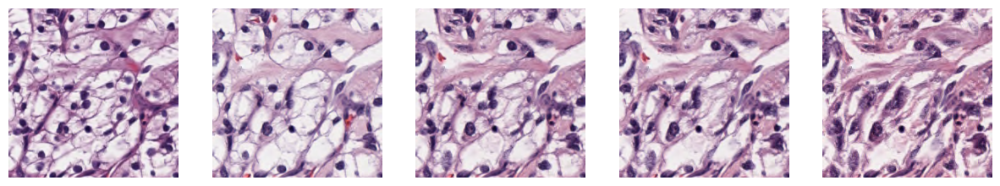

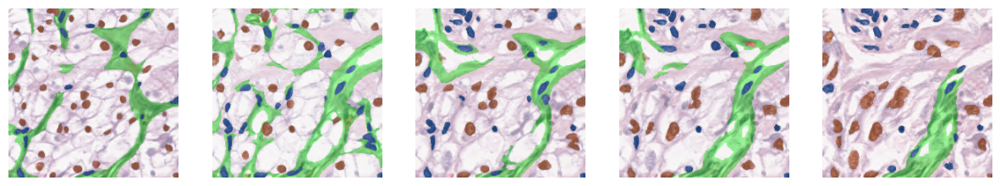

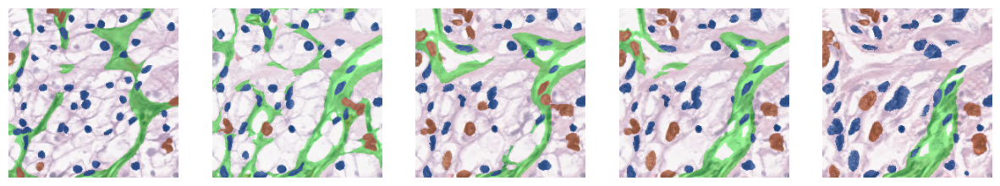

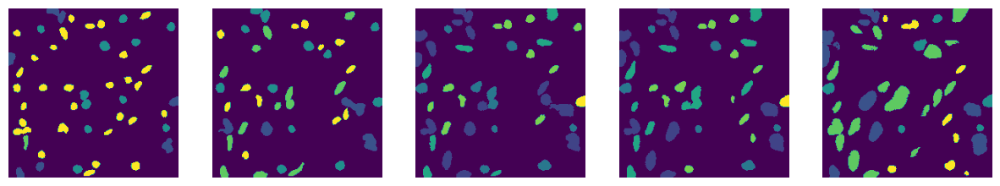

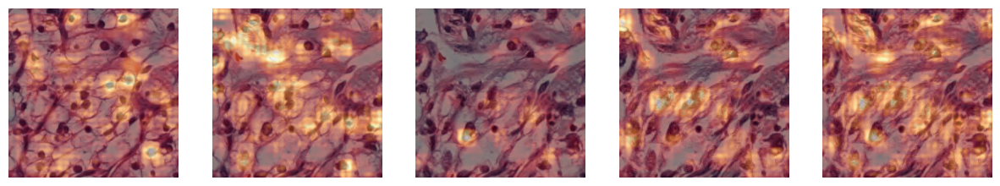

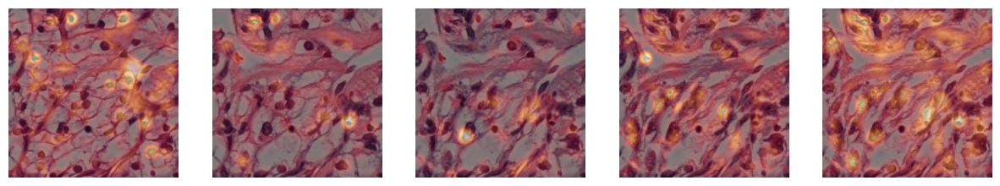

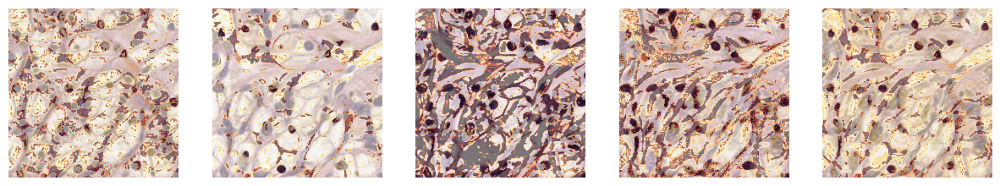

In [13]:
# plot images with masks and heatmaps
plt.figure(figsize=(15,3))
idx = np.random.randint(0,traverse_data['full_grade_list'].shape[0])
idx = 42 #159, 236, 42, 236, 805, 955, 27, 419,  913 suggested idx for grade 1 to 4 transition
plt.subplot(1,5,1)
img = traverse_data['patient_across_img'][idx]
plt.imshow(img)
# plt.title('Syn-Grade 1')
plt.axis('off')
for i in range(4):
    plt.subplot(1,5,i+2)
    img = traverse_data['img'][traverse_data['full_grade_list'][idx][i,0],traverse_data['full_grade_list'][idx][i,1],:,:,:]
    plt.imshow(img)
    # if i == 0:
    #     plt.title('Real-Grade 1')
    # else:
    #     plt.title('Syn-Grade {}'.format(i+1))
    plt.axis('off')
    
plt.figure(figsize=(15,3))
plt.subplot(1,5,1)
img = traverse_data['patient_across_img'][idx]
nuclei_mask = traverse_data['patient_across_img_Nuc_seg'][idx]
# immune_mask = traverse_data['jay_patient_across_img_pred_masks'][idx] == 2
# nObj, labelTest, statsTa, centroids=cv2.connectedComponentsWithStats(\
#         np.uint8(nuclei_mask>0),8,cv2.CV_32S)
# for j in range(1,nObj):
#     immune_detect = np.sum((labelTest == j)*(immune_mask > 0))
#     if immune_detect > 0:
#         nuclei_mask[labelTest == j] = 3
            
vas_mask = traverse_data['patient_across_img_vas'][idx]
mask = plot_mask(img, nuclei_mask, vas_mask)
plt.imshow(img)
plt.imshow(mask, alpha=0.5)
plt.axis('off')

for i in range(4):
    plt.subplot(1,5,i+2)
    img = traverse_data['img'][traverse_data['full_grade_list'][idx][i,0],traverse_data['full_grade_list'][idx][i,1],:,:,:]
    nuclei_mask = traverse_data['full_grade_list_Nuc_seg'][idx,i]
    # immune_mask = traverse_data['jay_pred_masks'][idx,i] == 2
    # nObj, labelTest, statsTa, centroids=cv2.connectedComponentsWithStats(\
    #     np.uint8(nuclei_mask>0),8,cv2.CV_32S)
    # for j in range(1,nObj):
    #     immune_detect = np.sum((labelTest == j)*(immune_mask > 0))
    #     if immune_detect > 0:
    #         nuclei_mask[labelTest == j] = 3
    vas_mask = traverse_data['full_grade_list_vas'][idx,i]
    mask = plot_mask(img, nuclei_mask, vas_mask)
    plt.imshow(img)
    plt.imshow(mask, alpha=0.5)
    plt.axis('off')

    
plt.figure(figsize=(15,3))
plt.subplot(1,5,1)
img = traverse_data['patient_across_img'][idx]
nuclei_mask = hovernet_testing['full_grade_list_HoverNet_Nucseg_patient_across_converted3class'][idx]
# immune_mask = traverse_data['jay_patient_across_img_pred_masks'][idx] == 2
# nObj, labelTest, statsTa, centroids=cv2.connectedComponentsWithStats(\
#         np.uint8(nuclei_mask>0),8,cv2.CV_32S)
# for j in range(1,nObj):
#     immune_detect = np.sum((labelTest == j)*(immune_mask > 0))
#     if immune_detect > 0:
#         nuclei_mask[labelTest == j] = 3
            
vas_mask = traverse_data['patient_across_img_vas'][idx]
mask = plot_mask(img, nuclei_mask, vas_mask)
plt.imshow(img)
plt.imshow(mask, alpha=0.5)
plt.axis('off')

for i in range(4):
    plt.subplot(1,5,i+2)
    img = traverse_data['img'][traverse_data['full_grade_list'][idx][i,0],traverse_data['full_grade_list'][idx][i,1],:,:,:]
    nuclei_mask = hovernet_testing['full_grade_list_HoverNet_Nucseg_converted3class'][idx,i]
    # immune_mask = traverse_data['jay_pred_masks'][idx,i] == 2
    # nObj, labelTest, statsTa, centroids=cv2.connectedComponentsWithStats(\
    #     np.uint8(nuclei_mask>0),8,cv2.CV_32S)
    # for j in range(1,nObj):
    #     immune_detect = np.sum((labelTest == j)*(immune_mask > 0))
    #     if immune_detect > 0:
    #         nuclei_mask[labelTest == j] = 3
    vas_mask = traverse_data['full_grade_list_vas'][idx,i]
    mask = plot_mask(img, nuclei_mask, vas_mask)
    plt.imshow(img)
    plt.imshow(mask, alpha=0.5)
    plt.axis('off')

plt.figure(figsize=(15,3))
plt.subplot(1,5,1)
img = traverse_data['patient_across_img'][idx]
nuclei_mask = hovernet_testing['full_grade_list_HoverNet_Nucseg_patient_across'][idx]
# immune_mask = traverse_data['jay_patient_across_img_pred_masks'][idx] == 2
# nObj, labelTest, statsTa, centroids=cv2.connectedComponentsWithStats(\
#         np.uint8(nuclei_mask>0),8,cv2.CV_32S)
# for j in range(1,nObj):
#     immune_detect = np.sum((labelTest == j)*(immune_mask > 0))
#     if immune_detect > 0:
#         nuclei_mask[labelTest == j] = 3
            
vas_mask = traverse_data['patient_across_img_vas'][idx]
mask = plot_mask(img, nuclei_mask, vas_mask)
plt.imshow(img)
plt.imshow(nuclei_mask)
plt.axis('off')

for i in range(4):
    plt.subplot(1,5,i+2)
    img = traverse_data['img'][traverse_data['full_grade_list'][idx][i,0],traverse_data['full_grade_list'][idx][i,1],:,:,:]
    nuclei_mask = hovernet_testing['full_grade_list_HoverNet_Nucseg'][idx,i]
    # immune_mask = traverse_data['jay_pred_masks'][idx,i] == 2
    # nObj, labelTest, statsTa, centroids=cv2.connectedComponentsWithStats(\
    #     np.uint8(nuclei_mask>0),8,cv2.CV_32S)
    # for j in range(1,nObj):
    #     immune_detect = np.sum((labelTest == j)*(immune_mask > 0))
    #     if immune_detect > 0:
    #         nuclei_mask[labelTest == j] = 3
    vas_mask = traverse_data['full_grade_list_vas'][idx,i]
    mask = plot_mask(img, nuclei_mask, vas_mask)
    plt.imshow(img)
    plt.imshow(nuclei_mask)
    plt.axis('off')

    
plt.figure(figsize=(15,3))
plt.subplot(1,5,1)
img = traverse_data['patient_across_img'][idx]
plt.imshow(img)
plt.imshow(traverse_data['mean_abs_transform_AAEfilter09_patient_across'][idx], cmap='afmhot', alpha=0.5)
plt.axis('off')
for i in range(1,4):
    img = traverse_data['img'][traverse_data['full_grade_list'][idx][i,0],traverse_data['full_grade_list'][idx][i,1],:,:,:]
    plt.subplot(1,5,i+1)
    plt.imshow(img)
    plt.imshow(traverse_data['mean_abs_transform_AAEfilter09_grade_across'][idx][i-1], cmap='afmhot', alpha=0.5)
    plt.axis('off')
    
img = traverse_data['img'][traverse_data['full_grade_list'][idx][3,0],traverse_data['full_grade_list'][idx][3,1],:,:,:]
plt.subplot(1,5,5)
plt.imshow(img)
plt.imshow(traverse_data['mean_abs_transform_AAEfilter09_grade_across_jump'][idx], cmap='afmhot', alpha=0.5)
plt.axis('off')
plt.figure(figsize=(15,3))
plt.subplot(1,5,1)
img = traverse_data['patient_across_img'][idx]
plt.imshow(img)
plt.imshow(traverse_data['mean_abs_transform_clsfilter13_patient_across'][idx], cmap='afmhot', alpha=0.5)
plt.axis('off')
for i in range(1,4):
    img = traverse_data['img'][traverse_data['full_grade_list'][idx][i,0],traverse_data['full_grade_list'][idx][i,1],:,:,:]
    plt.subplot(1,5,i+1)
    plt.imshow(img)
    plt.imshow(traverse_data['mean_abs_transform_clsfilter13_grade_across'][idx][i-1], cmap='afmhot', alpha=0.5)
    plt.axis('off')
plt.subplot(1,5,5)
plt.imshow(img)
plt.imshow(traverse_data['mean_abs_transform_clsfilter13_grade_across_jump'][idx], cmap='afmhot', alpha=0.5)
plt.axis('off')

plt.figure(figsize=(15,3))
plt.subplot(1,5,1)
img = traverse_data['patient_across_img'][idx]
plt.imshow(img)
raw_RGB_delta = img - traverse_data['img'][traverse_data['full_grade_list'][idx][0,0],traverse_data['full_grade_list'][idx][0,1],:,:,:]
plt.imshow(np.mean(np.abs(raw_RGB_delta), axis=-1), alpha=0.5, cmap='afmhot')
plt.axis('off')

for i in range(1,4):
    img = traverse_data['img'][traverse_data['full_grade_list'][idx][i,0],traverse_data['full_grade_list'][idx][i,1],:,:,:]
    plt.subplot(1,5,i+1)
    plt.imshow(img)
    raw_RGB_delta = img - traverse_data['img'][traverse_data['full_grade_list'][idx][i-1,0],traverse_data['full_grade_list'][idx][i-1,1],:,:,:]
    plt.imshow(np.mean(np.abs(raw_RGB_delta), axis=-1), alpha=0.5, cmap='afmhot')
    plt.axis('off')
plt.subplot(1,5,5)
plt.imshow(img)
raw_RGB_delta = img - traverse_data['img'][traverse_data['full_grade_list'][idx][0,0],traverse_data['full_grade_list'][idx][0,1],:,:,:]
plt.imshow(np.mean(np.abs(raw_RGB_delta), axis=-1), alpha=0.5, cmap='afmhot')
plt.axis('off')

(-0.5, 223.5, 223.5, -0.5)

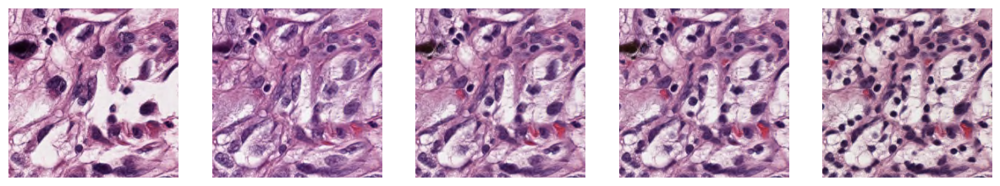

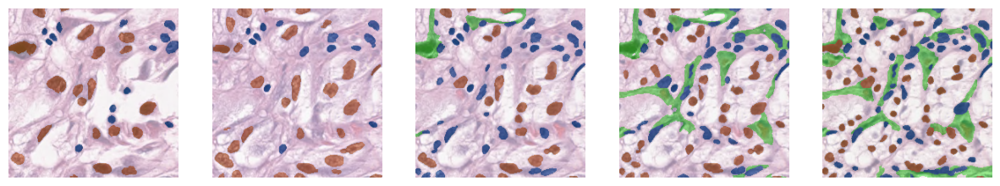

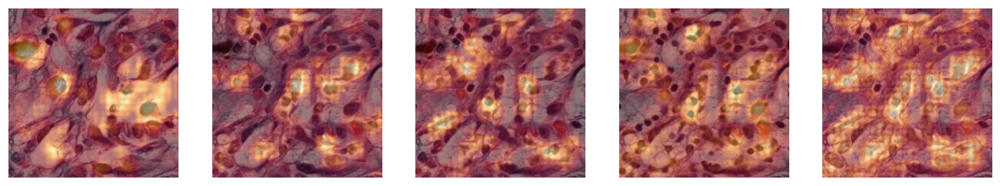

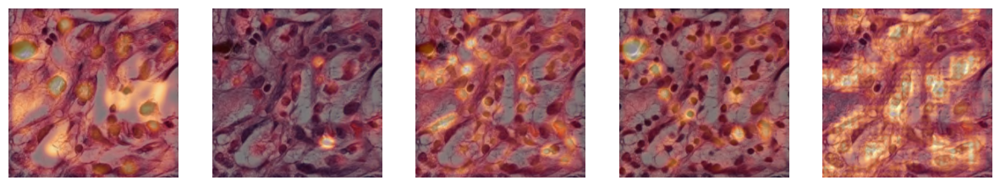

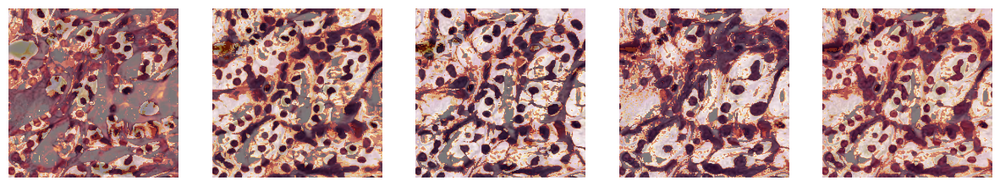

In [14]:

save_dir = file_paths['synthetic_data']['synthetic_data_grade4to1']
with open(save_dir,'rb') as f:
    traverse_data = pickle.load(f)
plt.figure(figsize=(15,3))
# idx = np.random.randint(0,traverse_data['full_grade_list'].shape[0])
idx = 5 #482, 250, 5, 551, 106, 258, 66, 265, 532, 371 suggested idx for grade 4 to 1 transition
# print(idx)
plt.subplot(1,5,1)
img = traverse_data['patient_across_img'][idx]
plt.imshow(img)
# plt.title('Syn-Grade 4')
plt.axis('off')
for i in range(4):
    plt.subplot(1,5,i+2)
    img = traverse_data['img'][traverse_data['full_grade_list'][idx][3-i,0],traverse_data['full_grade_list'][idx][3-i,1],:,:,:]
    plt.imshow(img)
    # if i == 0:
    #     plt.title('Real-Grade 4')
    # else:
    #     plt.title('Syn-Grade {}'.format(3-i+1))
    plt.axis('off')
    
plt.figure(figsize=(15,3))
plt.subplot(1,5,1)
img = traverse_data['patient_across_img'][idx]
nuclei_mask = traverse_data['patient_across_img_Nuc_seg'][idx]
# immune_mask = traverse_data['jay_patient_across_img_pred_masks'][idx] == 2
# nObj, labelTest, statsTa, centroids=cv2.connectedComponentsWithStats(\
#         np.uint8(nuclei_mask>0),8,cv2.CV_32S)
# for j in range(1,nObj):
#     immune_detect = np.sum((labelTest == j)*(immune_mask > 0))
#     if immune_detect > 0:
#         nuclei_mask[labelTest == j] = 3
            
vas_mask = traverse_data['patient_across_img_vas'][idx]
mask = plot_mask(img, nuclei_mask, vas_mask)
plt.imshow(img)
plt.imshow(mask, alpha=0.5)
plt.axis('off')

for i in range(4):
    plt.subplot(1,5,i+2)
    grd = 3-i
    img = traverse_data['img'][traverse_data['full_grade_list'][idx][grd,0],traverse_data['full_grade_list'][idx][grd,1],:,:,:]
    nuclei_mask = traverse_data['full_grade_list_Nuc_seg'][idx,grd]
    # immune_mask = traverse_data['jay_pred_masks'][idx,grd] == 2
    # nObj, labelTest, statsTa, centroids=cv2.connectedComponentsWithStats(\
    #     np.uint8(nuclei_mask>0),8,cv2.CV_32S)
    # for j in range(1,nObj):
    #     immune_detect = np.sum((labelTest == j)*(immune_mask > 0))
    #     if immune_detect > 0:
    #         nuclei_mask[labelTest == j] = 3
    vas_mask = traverse_data['full_grade_list_vas'][idx,grd]
    mask = plot_mask(img, nuclei_mask, vas_mask)
    plt.imshow(img)
    plt.imshow(mask, alpha=0.5)
    plt.axis('off')
    
plt.figure(figsize=(15,3))
plt.subplot(1,5,1)
img = traverse_data['patient_across_img'][idx]
plt.imshow(img)
plt.imshow(traverse_data['mean_abs_transform_AAEfilter09_patient_across'][idx], cmap='afmhot', alpha=0.5)
plt.axis('off')
for i in range(1,4):
    grd = 3-i
    img = traverse_data['img'][traverse_data['full_grade_list'][idx][grd,0],traverse_data['full_grade_list'][idx][grd,1],:,:,:]
    plt.subplot(1,5,i+1)
    plt.imshow(img)
    plt.imshow(traverse_data['mean_abs_transform_AAEfilter09_grade_across'][idx][grd-1], cmap='afmhot', alpha=0.5)
    plt.axis('off')
plt.subplot(1,5,5)
img = traverse_data['img'][traverse_data['full_grade_list'][idx][3,0],traverse_data['full_grade_list'][idx][3,1],:,:,:]
plt.imshow(img)
plt.imshow(traverse_data['mean_abs_transform_AAEfilter09_grade_across_jump'][idx], cmap='afmhot', alpha=0.5)
plt.axis('off')
    
plt.figure(figsize=(15,3))
plt.subplot(1,5,1)
img = traverse_data['patient_across_img'][idx]
plt.imshow(img)
plt.imshow(traverse_data['mean_abs_transform_clsfilter13_patient_across'][idx], cmap='afmhot', alpha=0.5)
plt.axis('off')
for i in range(1,4):
    grd = 3-i
    img = traverse_data['img'][traverse_data['full_grade_list'][idx][i,0],traverse_data['full_grade_list'][idx][grd,1],:,:,:]
    plt.subplot(1,5,i+1)
    plt.imshow(img)
    plt.imshow(traverse_data['mean_abs_transform_clsfilter13_grade_across'][idx][grd-1], cmap='afmhot', alpha=0.5)
    plt.axis('off')
    
plt.subplot(1,5,5)
img = traverse_data['img'][traverse_data['full_grade_list'][idx][3,0],traverse_data['full_grade_list'][idx][3,1],:,:,:]
plt.imshow(img)
plt.imshow(traverse_data['mean_abs_transform_AAEfilter09_grade_across_jump'][idx], cmap='afmhot', alpha=0.5)
plt.axis('off')

plt.figure(figsize=(15,3))
plt.subplot(1,5,1)
img = traverse_data['patient_across_img'][idx]
plt.imshow(img)
raw_RGB_delta = img - traverse_data['img'][traverse_data['full_grade_list'][idx][0,0],traverse_data['full_grade_list'][idx][0,1],:,:,:]
plt.imshow(np.mean(np.abs(raw_RGB_delta), axis=-1), alpha=0.5, cmap='afmhot')
# plt.imshow(raw_RGB_delta)
plt.axis('off')

for i in range(1,4):
    img = traverse_data['img'][traverse_data['full_grade_list'][idx][i,0],traverse_data['full_grade_list'][idx][i,1],:,:,:]
    plt.subplot(1,5,i+1)
    plt.imshow(img)
    raw_RGB_delta = img - traverse_data['img'][traverse_data['full_grade_list'][idx][i-1,0],traverse_data['full_grade_list'][idx][i-1,1],:,:,:]
    plt.imshow(np.mean(np.abs(raw_RGB_delta), axis=-1), alpha=0.5, cmap='afmhot')
    # plt.imshow(raw_RGB_delta)
    plt.axis('off')
plt.subplot(1,5,5)
plt.imshow(img)
raw_RGB_delta = img - traverse_data['img'][traverse_data['full_grade_list'][idx][0,0],traverse_data['full_grade_list'][idx][0,1],:,:,:]
plt.imshow(np.mean(np.abs(raw_RGB_delta), axis=-1), alpha=0.5, cmap='afmhot')
# plt.imshow(raw_RGB_delta)
plt.axis('off')

In [15]:

# %% compute average nuclei size per patch and average number of nucleoli per nucleus

#compute the mean of nuclei area in each patch
nucleoli_num_list = []
tumor_type_list = []
class_list = []
Area_list = []
data_type_list = []
num_nuclei_list = []
    
save_dir = file_paths['real_data']['real_data_120000patches']
with open(save_dir,'rb') as f:
  data = pickle.load(f)
data_type_name = ['Real', 'Syn']
num_sample = 500
for data_type in data_type_name:
    if data_type == 'Syn':
        obsevered_nuclei_mask = []
        observed_class = []
        obsevered_img = []

        traverse_data_dir = file_paths['synthetic_data']['synthetic_data_grade1to4']
        with open(traverse_data_dir,'rb') as f:
            traverse_data1to4 = pickle.load(f)
        for i in [2,3]:
            idx = np.random.choice(len(traverse_data1to4['full_grade_list']), num_sample, replace = False)
            obsevered_img.append(traverse_data1to4['img'][traverse_data1to4['full_grade_list'][idx,i,0],traverse_data1to4['full_grade_list'][idx,i,1]])
            obsevered_nuclei_mask.append(traverse_data1to4['full_grade_list_Nuc_seg'][idx,i])
            observed_class.append(np.ones(num_sample)*i)
        traverse_data_dir = file_paths['synthetic_data']['synthetic_data_grade4to1']
        with open(traverse_data_dir,'rb') as f:
            traverse_data4to1 = pickle.load(f)

        for i in [0,1]:
            idx = np.random.choice(len(traverse_data4to1['full_grade_list']), num_sample, replace = False)
            obsevered_img.append(traverse_data4to1['img'][traverse_data4to1['full_grade_list'][idx,i,0],traverse_data4to1['full_grade_list'][idx,i,1]])
            obsevered_nuclei_mask.append(traverse_data4to1['full_grade_list_Nuc_seg'][idx,i])
            observed_class.append(np.ones(num_sample)*i)
        obsevered_img = np.concatenate(obsevered_img, axis = 0)
        observed_class = np.concatenate(observed_class, axis = 0)
        obsevered_nuclei_mask = np.concatenate(obsevered_nuclei_mask, axis = 0)
        
        
    elif data_type == 'Real':
        
        #load a real data with num_sample patches in each grade
        #real data is smaller subset of origin data with 1000 patches in each grade
        save_dir = file_paths['real_data']['real_data_4000patches']
        with open(save_dir,'rb') as f:
            real_data = pickle.load(f)  
        obsevered_nuclei_mask = real_data['Nuc_Seg']
        observed_class = data['classes'][real_data['idx']]
        observer_idx = []
        for i in range(4):
            idx_i = np.where(observed_class == i)[0]
            observer_idx.append(idx_i[:num_sample])
            
        observer_idx = np.concatenate(observer_idx, axis = 0)
        obsevered_nuclei_mask = obsevered_nuclei_mask[observer_idx]
            
        observed_class = observed_class[observer_idx]
        obsevered_img = real_data['img']
        obsevered_img = obsevered_img[observer_idx]   
    for i in range(obsevered_nuclei_mask.shape[0]):
        nuclei_type_list, Area, grade, num_nuclei = mean_nuclei_area_extract(obsevered_nuclei_mask[i], observed_class[i], data_type)
        nucleoli_num, nucleoli_type, nuclei_num = nucleoli_extract(obsevered_img[i], obsevered_nuclei_mask[i], data_type)
        nucleoli_num_list.append(nucleoli_num)        
        tumor_type_list.append(nuclei_type_list)
        Area_list.append(Area)
        class_list.append(grade)
        num_nuclei_list.append(num_nuclei)
        data_type_list.append([data_type]*len(Area))
tumor_type_list = np.concatenate(tumor_type_list,axis = None)
Area_list = np.concatenate(Area_list,axis = None)
class_list = np.concatenate(class_list,axis = None)
num_nuclei = np.concatenate(num_nuclei_list,axis = None)
data_type_list = np.concatenate(data_type_list,axis = None)
nucleoli_num_list = np.concatenate(nucleoli_num_list,axis = None)



/tmp/ipykernel_72549/1488742489.py:56: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticks().astype(int), fontsize=20)


['***' '***' '***' '***']


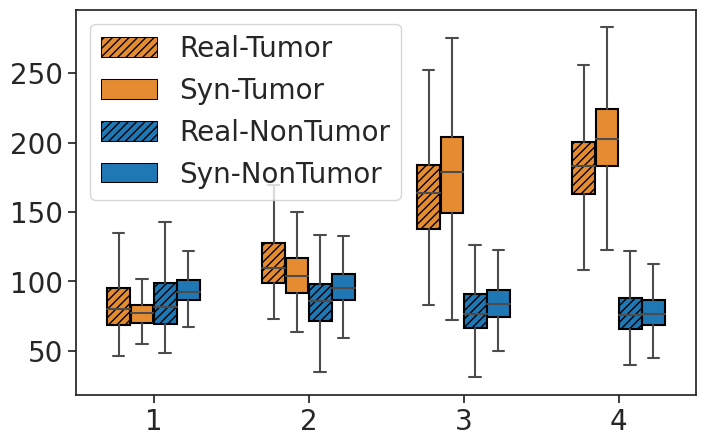

In [ ]:
# #%% plot the average size of nuclei for each grade

# plot nuclei size with seaborn

data_complex = pd.DataFrame({
    'Grade':  list(class_list+1),
    'data_type': list(tumor_type_list),
    'nuclei_size': list(Area_list),
})
data_type_order =  ['Real-Tumor','Syn-Tumor','Real-NonTumor','Syn-NonTumor']
data_complex['data_type'] = pd.Categorical(data_complex['data_type'], categories=data_type_order, ordered=True)

import seaborn as sns
# # hatches must equal the number of hues (3 in this case)
hatches = ['////', '', '////', '']
plt.figure(figsize=(8, 5))
# hueorder = ['Other', 'Tumor', 'Immune']
hueorder = ['NonTumor', 'Tumor']

ax = sns.boxplot(x="Grade", y="nuclei_size", hue="data_type", data=data_complex, showfliers = False, width= 0.6)

# select the correct patches
patches = [patch for patch in ax.artists]
# the number of patches should be evenly divisible by the number of hatches
tumColor=list(np.array([229,140,50])/255)
nonTumoColor=list(np.array([31,119,180])/255)
# immuneColor=list(np.array([61,239,253])/255)
# immuneColor=list(np.array([239,87,255])/255)
color_dict = {'NonTumor': nonTumoColor, 'Tumor': tumColor}
# color_dict = {'Other': nonTumoColor, 'Tumor': tumColor, 'Immune': immuneColor}
data_list =['Real-Tumor','Syn-Tumor','Real-NonTumor','Syn-NonTumor']*4
# data_list = ['Real-Other']*4+['Real-Tumor']*4+['Real-Immune']*4+['Syn-Other']*4+['Syn-Tumor']*4+['Syn-Immune']*4
    
h = ['////',    '','////', '']*4
# h = ['////']*12+['']*12
Color_list = [color_dict[data_list[i].split('-')[1]] for i in range(len(data_list))]
for patch, hatch, color in zip(patches, h, Color_list):
    patch.set_hatch(hatch)
    fc = color
    patch.set_edgecolor((0,0,0,1))
    patch.set_facecolor(fc)
l = ax.legend(fontsize=20)

hatches = ['////',  '',   '////','']
# hatches = ['////', '////', '////','',  '',  '']
Colors = [ tumColor,tumColor,nonTumoColor, nonTumoColor]
# Colors = [nonTumoColor, tumColor,immuneColor, nonTumoColor, tumColor,immuneColor]
for lp, hatch, color in zip(l.get_patches(), hatches, Colors):
    lp.set_hatch(hatch)
    fc = lp.get_facecolor()
    lp.set_edgecolor((0,0,0,1))
    lp.set_facecolor(color)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticklabels([1, 2, 3, 4], fontsize=20)
ax.set_yticklabels(ax.get_yticks().astype(int), fontsize=20)
#show the p-value on tumor nuclei  area between real and synthetic data
from scipy.stats import mannwhitneyu
p_value_list = []
for i in range(4):
    idx = np.where((class_list == i) & (tumor_type_list == 'Real-Tumor'))[0]
    real_list = Area_list[idx]
    idx = np.where((class_list == i) & (tumor_type_list == 'Syn-Tumor'))[0]
    syn_list = Area_list[idx]
    stat, p = mannwhitneyu(real_list, syn_list)
    p_value_list.append(significance_value(p))
p_value_list = np.array(p_value_list)
print(p_value_list)
plt.show()





/tmp/ipykernel_72549/3161030614.py:57: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(np.round(ax.get_yticks(), 1), fontsize=20)


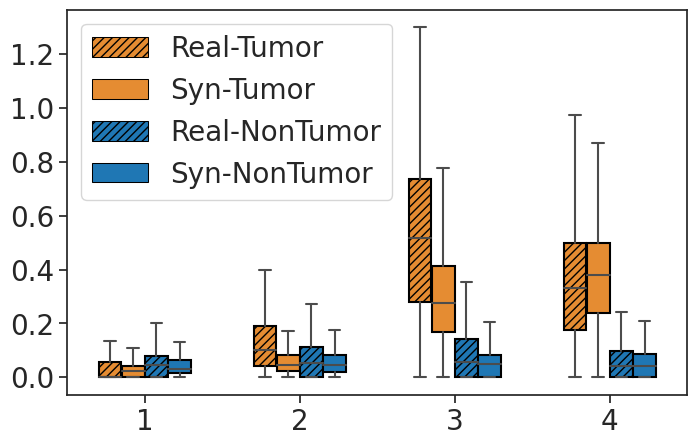

In [ ]:
#plot average number of nucleoli per nucleus

#plot by sns
data_complex = pd.DataFrame({
    'Grade':  list(class_list+1),
    'data_type': list(tumor_type_list),
    'nucleoli_size': list(nucleoli_num_list),
})

data_type_order =  ['Real-Tumor','Syn-Tumor','Real-NonTumor','Syn-NonTumor']
data_complex['data_type'] = pd.Categorical(data_complex['data_type'], categories=data_type_order, ordered=True)

import seaborn as sns
# # hatches must equal the number of hues (3 in this case)
hatches = ['////', '', '////', '']
plt.figure(figsize=(8, 5))
# hueorder = ['Other', 'Tumor', 'Immune']
hueorder = ['NonTumor', 'Tumor']

ax = sns.boxplot(x="Grade", y="nucleoli_size", hue="data_type", data=data_complex, showfliers = False, width= 0.6)

# select the correct patches
patches = [patch for patch in ax.artists]
# the number of patches should be evenly divisible by the number of hatches
tumColor=list(np.array([229,140,50])/255)
nonTumoColor=list(np.array([31,119,180])/255)
# immuneColor=list(np.array([61,239,253])/255)
# immuneColor=list(np.array([239,87,255])/255)
color_dict = {'NonTumor': nonTumoColor, 'Tumor': tumColor}
# color_dict = {'Other': nonTumoColor, 'Tumor': tumColor, 'Immune': immuneColor}
data_list =['Real-Tumor','Syn-Tumor','Real-NonTumor','Syn-NonTumor']*4
# data_list = ['Real-Other']*4+['Real-Tumor']*4+['Real-Immune']*4+['Syn-Other']*4+['Syn-Tumor']*4+['Syn-Immune']*4
    
h = ['////',    '','////', '']*4
# h = ['////']*12+['']*12
Color_list = [color_dict[data_list[i].split('-')[1]] for i in range(len(data_list))]
for patch, hatch, color in zip(patches, h, Color_list):
    patch.set_hatch(hatch)
    fc = color
    patch.set_edgecolor((0,0,0,1))
    patch.set_facecolor(fc)
l = ax.legend(fontsize=20)

hatches = ['////',  '',   '////','']
# hatches = ['////', '////', '////','',  '',  '']
Colors = [ tumColor,tumColor,nonTumoColor, nonTumoColor]
# Colors = [nonTumoColor, tumColor,immuneColor, nonTumoColor, tumColor,immuneColor]
for lp, hatch, color in zip(l.get_patches(), hatches, Colors):
    lp.set_hatch(hatch)
    fc = lp.get_facecolor()
    lp.set_edgecolor((0,0,0,1))
    lp.set_facecolor(color)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticklabels([1, 2, 3, 4], fontsize=20)
#set the yticks with one decimal
ax.set_yticklabels(np.round(ax.get_yticks(), 1), fontsize=20)
    
plt.show()

([], [])

<Figure size 600x300 with 0 Axes>

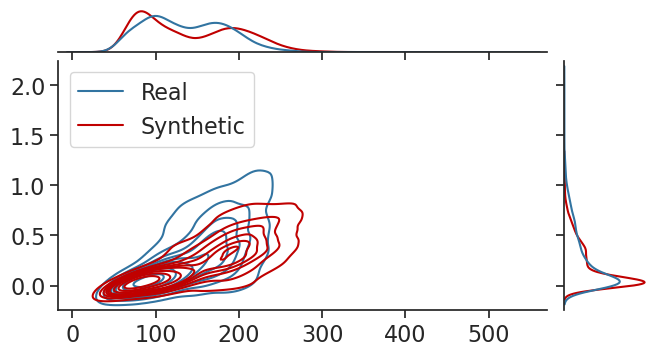

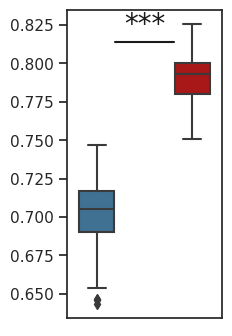

In [20]:
#plot correlation between average number of nucleoli per nucleus and average nuclei size

import seaborn as sns
idx = np.where((tumor_type_list == 'Real-Tumor')|(tumor_type_list == 'Syn-Tumor'))

df = pd.DataFrame({'Nuclei size': Area_list[idx], 'Number of nucleoli': nucleoli_num_list[idx], 'Data type': tumor_type_list[idx]})
#Repace 'Real-Tumor' in data type by Real
df['Data type'] = df['Data type'].replace({'Real-Tumor': 'Real', 'Syn-Tumor': 'Synthetic'})
# Show the joint distribution using kernel density estimation
plt.figure(figsize = (6,3))
my_col = ['#3274A1','#C00000']
g = sns.jointplot(
    data=df ,
    x="Nuclei size", y="Number of nucleoli", hue="Data type", kind="kde", palette = my_col
)
g.fig.set_size_inches(7,3.5) 

plt.xlabel('')
plt.ylabel('')
#show legend
plt.legend(
    handles=g.ax_joint.legend_.legendHandles,
    labels=['Real', 'Synthetic'],
    fontsize = 16,
    loc="upper left"
)
plt.xticks(fontsize = 16)
plt.yticks(fontsize = 16)
# idx = np.where((tumor_type_list == 'Real-Tumor')|(tumor_type_list == 'Syn-Tumor'))
# plt.xlim([0,max(Area_list[idx])])
# plt.ylim([0,max(nucleoli_num_list[idx])])

correlation_list = []
grade_list = []
sub_data_type_list = []
#take 100 samples from each grade to compute correlation between nuclei area and number of nucleoli

for data_name in ['Real-Tumor', 'Syn-Tumor']:
    for i in range(100):
        idx_list = []
        for grd in range(4):
            idx = np.where((tumor_type_list == data_name) & (class_list == grd))[0]
            idx_ran = np.random.choice(idx,200)
            idx_list.append(idx_ran)
        idx_list = np.concatenate(idx_list, axis = 0)
        corr, _ = stats.pearsonr(Area_list[idx_list], nucleoli_num_list[idx_list])
        correlation_list.append(corr)
        sub_data_type_list.append(data_name)
correlation_list = np.array(correlation_list)
grade_list = np.array(grade_list)
sub_data_type_list = np.array(sub_data_type_list)
df = pd.DataFrame({'Correlation': correlation_list,'Data Type': sub_data_type_list})

plt.figure(figsize = (2,4))
my_col = ['#3274A1','#C00000']
sns.boxplot(x = 'Data Type', y = 'Correlation', hue = 'Data Type', data = df, width=1.2, palette= my_col)
# # plt.xlabel('Data Type', fontsize = 16)
# plt.ylabel('Pearson Correlation', fontsize = 16)
plt.xticks([0,1], ['Real', 'Synthetic'], fontsize = 16)
plt.xlabel('')
plt.ylabel('')
#add p-value on top of boxplot
import scipy.stats as stats
idx_real = np.where(sub_data_type_list == 'Real-Tumor')
idx_syn = np.where(sub_data_type_list == 'Syn-Tumor')
corr_real = correlation_list[idx_real]
corr_syn = correlation_list[idx_syn]
t_stast, p_val= stats.ttest_ind(corr_real, corr_syn, alternative='two-sided')
x1, x2 = 0, 1  # These are the x positions of the two groups in the boxplot
y, h, col = df['Correlation'].max()-0.01, 0.002, 'k'  # y: the height at which to draw the line; h: line height; col: line color

if p_val < 0.001:
    significance = '***'
elif p_val < 0.01:
    significance = '**'
elif p_val < 0.05:
    significance = '*'
else:
    significance = 'ns'  # Not significant
plt.plot([x1, x2], [y-h, y-h], lw=1.5, c=col)

plt.text((x1+x2)*.5,y, f"{significance}", ha='center', va='bottom', color=col, fontsize=20)
#do not display legend
plt.legend().remove()
plt.xlabel('')
plt.xticks([])

No handles with labels found to put in legend.
No handles with labels found to put in legend.
/project/bioinformatics/Rajaram_lab/shared/Environment/Conda/Thuongenv/lib/python3.9/site-packages/seaborn/distributions.py:1185: UserWarning: The following kwargs were not used by contour: 'plot_kws'
  cset = contour_func(
No handles with labels found to put in legend.
No handles with labels found to put in legend.


(0.0, 528.5)

<Figure size 500x500 with 0 Axes>

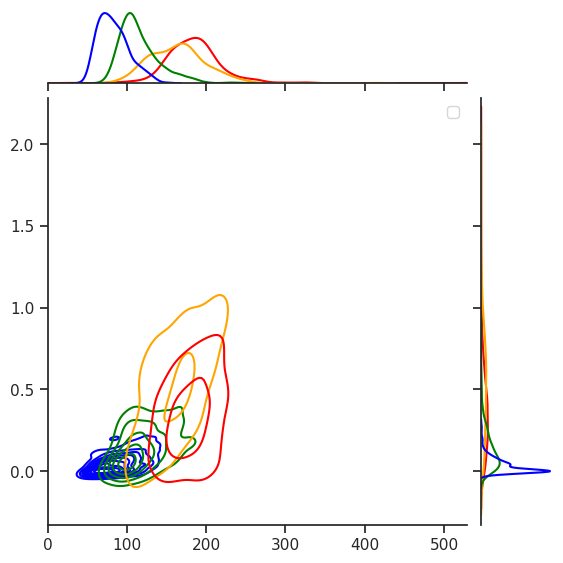

<Figure size 500x500 with 0 Axes>

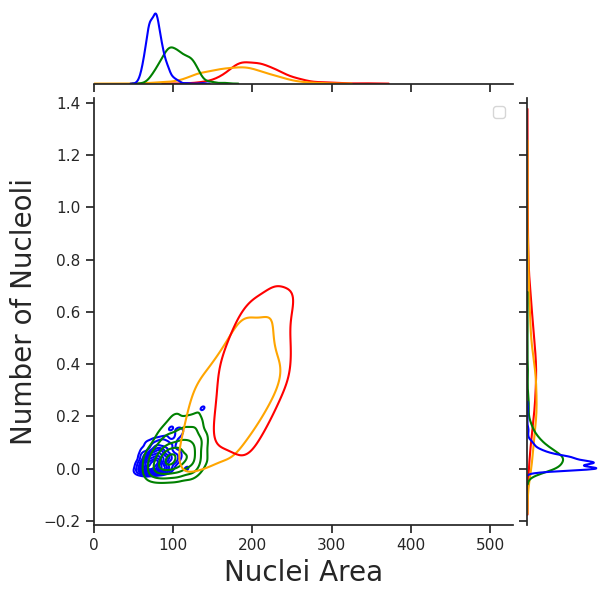

In [21]:

# import seaborn as sns
sns.set_theme(style="ticks")
idx = np.where((tumor_type_list == 'Real-Tumor'))
df = pd.DataFrame({'Nuclei Area': Area_list[idx], 'Number of Nucleoli': nucleoli_num_list[idx], 'Grade': class_list[idx]+1})
color_dict = {1:'blue', 2:'green', 3:'orange', 4:'red'}

plt.figure(figsize = (5,5))
# Show the joint distribution using kernel density estimation
g = sns.jointplot(
    data=df ,
    x="Nuclei Area", y="Number of Nucleoli", hue="Grade", kind="kde", palette = color_dict)
plt.xlabel('Nuclei Area', fontsize = 20)
plt.ylabel('Number of Nucleoli', fontsize = 20)
plt.legend()

plt.legend(markerscale=3)
idx = np.where((tumor_type_list == 'Real-Tumor')|(tumor_type_list == 'Syn-Tumor'))
plt.xlim([0,max(Area_list[idx])])
# plt.ylim([0,max(nucleoli_num_list[idx])])
plt.xlabel('')
plt.ylabel('')


import seaborn as sns
sns.set_theme(style="ticks")
idx = np.where((tumor_type_list == 'Syn-Tumor'))
df = pd.DataFrame({'Nuclei Area': Area_list[idx], 'Number of Nucleoli': nucleoli_num_list[idx], 'Grade': class_list[idx]+1})
color_dict = {1:'blue', 2:'green', 3:'orange', 4:'red'}

plt.figure(figsize = (5,5))
# Show the joint distribution using kernel density estimation
g = sns.jointplot(
    data=df ,
    x="Nuclei Area", y="Number of Nucleoli", hue="Grade", kind="kde", palette = color_dict,plot_kws={"levels": 20})
plt.xlabel('Nuclei Area', fontsize = 20)
plt.ylabel('Number of Nucleoli', fontsize = 20)
plt.legend()

plt.legend(markerscale=3)
idx = np.where((tumor_type_list == 'Real-Tumor')|(tumor_type_list == 'Syn-Tumor'))
plt.xlim([0,max(Area_list[idx])])
# plt.ylim([0,max(nucleoli_num_list[idx])])


/tmp/ipykernel_72549/3532127461.py:100: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(np.round(ax.get_yticks(), 1), fontsize=20)


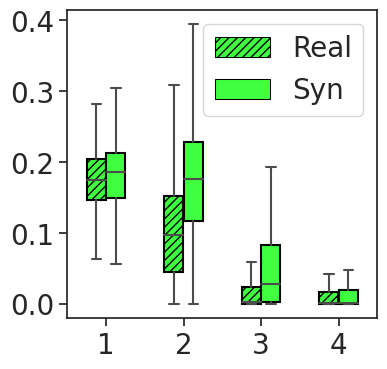

In [25]:
#%% plot the average percentage of vasculature for each grade
class_list = []
Vas_percentage_list = []
tumor_type_list = []

num_sample = 500
data_type_list = ['Real', 'Syn']
for data_type in data_type_list:
    if data_type == 'Syn':
        obsevered_vas_mask = []
        observed_class = []
        obsevered_img = []

        traverse_data_dir = file_paths['synthetic_data']['synthetic_data_grade1to4']
        with open(traverse_data_dir,'rb') as f:
            traverse_data1to4 = pickle.load(f)
        for i in [2,3]:
            idx = np.random.choice(len(traverse_data1to4['full_grade_list']), num_sample, replace = False)
            obsevered_img.append(traverse_data1to4['img'][traverse_data1to4['full_grade_list'][idx,i,0],traverse_data1to4['full_grade_list'][idx,i,1]])
            obsevered_vas_mask.append(traverse_data1to4['full_grade_list_vas'][idx,i])
            observed_class.append(np.ones(num_sample)*i)

        traverse_data_dir = file_paths['synthetic_data']['synthetic_data_grade4to1']
        with open(traverse_data_dir,'rb') as f:
            traverse_data4to1 = pickle.load(f)

        for i in [0,1]:
            idx = np.random.choice(len(traverse_data4to1['full_grade_list']), num_sample, replace = False)
            obsevered_img.append(traverse_data4to1['img'][traverse_data4to1['full_grade_list'][idx,i,0],traverse_data4to1['full_grade_list'][idx,i,1]])
            obsevered_vas_mask.append(traverse_data4to1['full_grade_list_vas'][idx,i])
            observed_class.append(np.ones(num_sample)*i)
            
        obsevered_img = np.concatenate(obsevered_img, axis = 0)
        observed_class = np.concatenate(observed_class, axis = 0)
        obsevered_vas_mask = np.concatenate(obsevered_vas_mask, axis = 0)
    elif data_type == 'Real':
        
        #load a real data with num_sample patches in each grade
        save_dir = file_paths['real_data']['real_data_4000patches']
        with open(save_dir,'rb') as f:
            real_data = pickle.load(f)    
        obsevered_vas_mask = real_data['vas']
        observed_class = data['classes'][real_data['idx']]
        observer_idx = []
        for i in range(4):
            idx_i = np.where(observed_class == i)[0]
            np.random.shuffle(idx_i)
            observer_idx.append(idx_i[:num_sample])
        observer_idx = np.concatenate(observer_idx, axis = 0)
        obsevered_vas_mask = obsevered_vas_mask[observer_idx]
        observed_class = observed_class[observer_idx]
        
    Vas_percentage = np.sum(obsevered_vas_mask, axis = (1,2))/(obsevered_vas_mask.shape[1]*obsevered_vas_mask.shape[2])
    Vas_percentage_list.append(Vas_percentage)
    class_list.append(observed_class)
    tumor_type_list.append([data_type]*Vas_percentage.shape[0])

        
tumor_type_list = np.concatenate(tumor_type_list,axis = None)
Vas_percentage_list = np.concatenate(Vas_percentage_list,axis = None)
class_list = np.concatenate(class_list,axis = None)

##plot by sns
data_complex = pd.DataFrame({
    'Grade':  list(class_list+1),
    'data_type': list(tumor_type_list),
    'value': list(Vas_percentage_list),
})

import seaborn as sns
# # hatches must equal the number of hues (3 in this case)
plt.figure(figsize=(4, 4))
ax = sns.boxplot(x="Grade", y="value", hue='data_type', data=data_complex, showfliers = False, width=0.5)

# select the correct patches
patches = [patch for patch in ax.artists]
# the number of patches should be evenly divisible by the number of hatches
vasColor=np.array([64,255,64])/255
Colors = [ vasColor, vasColor]
h = ['////','']*4
# iterate through the patches for each subplot
for patch, hatch in zip(patches, h):
    patch.set_hatch(hatch)
    fc = vasColor
    patch.set_edgecolor((0,0,0,1))
    patch.set_facecolor(fc)
l = ax.legend(fontsize=20, loc = 'upper right')

hatches = ['////', '']    
for lp, hatch in zip(l.get_patches(), hatches):
    lp.set_hatch(hatch)
    fc = lp.get_facecolor()
    lp.set_edgecolor((0,0,0,1))
    lp.set_facecolor(vasColor)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticklabels([1, 2, 3, 4], fontsize=20)
#reduce the number of ticks in y axis to 5
ax.yaxis.set_major_locator(plt.MaxNLocator(5))
ax.set_yticklabels(np.round(ax.get_yticks(), 1), fontsize=20)
plt.show()

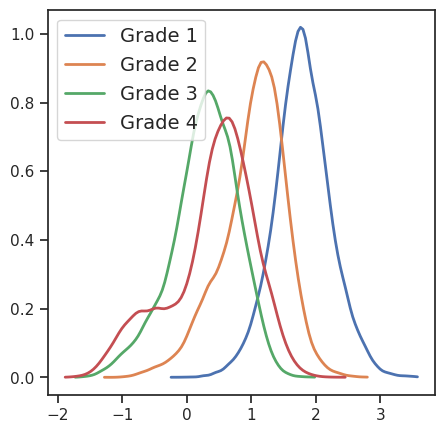

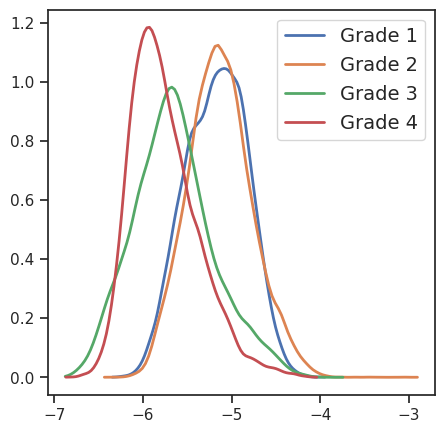

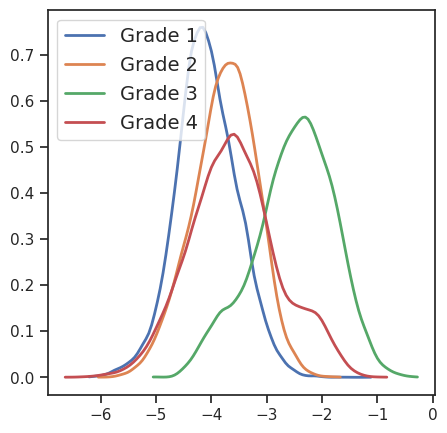

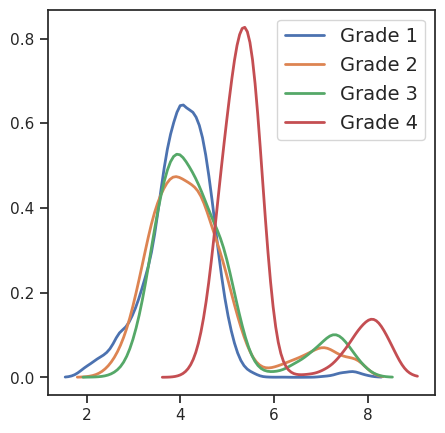

In [ ]:
#plot discriminant score of DIFFAE semantic vector for different grade

from scipy.stats import gaussian_kde
yaml_paths = './data/data_dir.yaml'
with open(yaml_paths, 'r') as yaml_file:
    file_paths = yaml.safe_load(yaml_file)
vec_list = np.load(file_paths['latent_space']['DIFFAE'])
linear_cls_weight = np.load(file_paths['WEIGHTS']['cls_DIFFAE_vec'])
class_list = data['classes'] 

score_list = []
for i in range(linear_cls_weight.shape[0]):
    score_list.append(np.dot(vec_list, linear_cls_weight[i]))
score_list = np.array(score_list)

#plot histogram line plot
for i in range(4):
    plt.figure(figsize=(5, 5))
    for j in range(4):
        vec_data = score_list[i][class_list == j]
        kde = gaussian_kde(vec_data)

        # Generate values for the x-axis
        x_vals = np.linspace(min(vec_data), max(vec_data), 100)

        # Evaluate the KDE over the x values
        kde_vals = kde(x_vals)

        # Plot the smooth KDE line
        plt.plot(x_vals, kde_vals, linewidth=2, label = f'Grade {j+1}')
        plt.legend(fontsize = 14)


  0%|          | 0/977 [00:00<?, ?it/s]/project/bioinformatics/Rajaram_lab/shared/Environment/Conda/Thuongenv/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/project/bioinformatics/Rajaram_lab/shared/Environment/Conda/Thuongenv/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
100%|██████████| 977/977 [00:00<00:00, 46084.51it/s]


<AxesSubplot:xlabel='GradePair', ylabel='log(P)'>

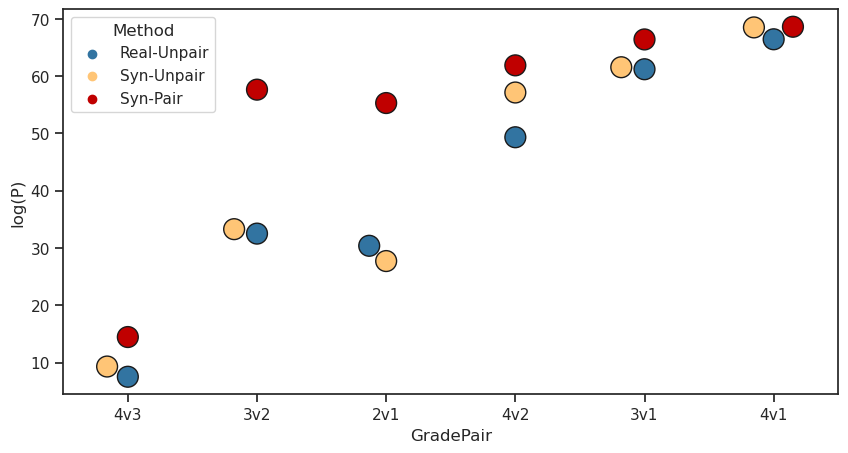

In [ ]:
#Counterfactual Analysis
from statsmodels.stats.descriptivestats import sign_test
save_dir = file_paths['synthetic_data']['synthetic_data_grade1to4']
with open(save_dir,'rb') as f:
    traverse_data = pickle.load(f)
num_sample = traverse_data['full_grade_list'].shape[0]
nGrades=4
full_grade_list = np.arange(0,traverse_data['full_grade_list'].shape[0])
#shuffle rows in full_grade_list 
#np.random.shuffle(full_grade_list)
full_grade_idx = traverse_data['full_grade_list'][full_grade_list[:num_sample]]
obsevered_nuclei_mask = traverse_data['full_grade_list_Nuc_seg'][full_grade_list[:num_sample]]

# %%
allTrajList=[]
for trajNumber in tqdm(range(num_sample)):
    trajAreaList=[]
    for grade in range(1,nGrades+1):


        tumorNucleiMask=np.uint8(obsevered_nuclei_mask[trajNumber,grade-1]==2)
        
        
        
        
        nObj, labels, compStats, centroids = \
            cv2.connectedComponentsWithStats(tumorNucleiMask, connectivity=8)
        areas=compStats[1:,-1]
        trajAreaList.append(areas)
    allTrajList.append(trajAreaList)
    
# %%

avgAreaList=np.zeros((num_sample,nGrades))
for trajNumber in tqdm(range(num_sample)):

    for grade in range(nGrades):
        avgAreaList[trajNumber,grade]=np.mean(allTrajList[trajNumber][grade]) 
isGood=np.all(np.isfinite(avgAreaList),axis=1)        
avgAreaList=avgAreaList[isGood]

# %%

#real data
realGrades=data['classes'][real_data['idx']]+1
realSeg=real_data['Nuc_Seg']
nRealPatches=realSeg.shape[0]
realTumorAreas=[]
for realPatchCounter in range(nRealPatches):
    tumorNucleiMask=np.uint8(realSeg[realPatchCounter]==2)  
    nObj, labels, compStats, centroids = \
        cv2.connectedComponentsWithStats(tumorNucleiMask, connectivity=8)
    areas=compStats[1:,-1]
    realTumorAreas.append(areas)

avgRealAreas=np.array([np.mean(a) for a in realTumorAreas])
# %%


nRuns=1000
nTrajsPerRun=100


logPMats={}
compTypes=['RUvsSU','RUvsSP','SPvsSU']
longNames={'SU':'Syn-Unpair','RU':'Real-Unpair','SP':'Syn-Pair'}
logPMats={c:np.NAN*np.zeros((nGrades,nGrades)) for c in compTypes}

gAList=[]
gBList=[]
compList=[]
pList=[]
for gA in range(1,5):
    for gB in range(1,gA):
        pTrueList=[]
        pShuffleList=[]
        pRealList=[]
        
        realAIdx=np.where(realGrades==gA)[0]
        realAreasA=avgRealAreas[realAIdx]
        realAreasA=realAreasA[np.isfinite(realAreasA)]
        
        realBIdx=np.where(realGrades==gB)[0]
        realAreasB=avgRealAreas[realBIdx]
        realAreasB=realAreasB[np.isfinite(realAreasB)]
        for runCounter in range(nRuns):
            randTrajIdx=np.random.choice(np.arange(avgAreaList.shape[0]),size=nTrajsPerRun,replace=False)
        
            trueA=avgAreaList[randTrajIdx,gA-1]
            trueB=avgAreaList[randTrajIdx,gB-1]
            #testTrue=stats.wilcoxon(trueA,trueB)
            #pTrueList.append(testTrue.pvalue)
            testTrue=sign_test(trueA,trueB)
            pTrueList.append(testTrue[1])
            
            #THIS COULD BE IMPLEMENTED BY RESAMPLING RANDOMLY INSTEAD OF SHUFFLING
            shuffledB=trueB.copy()
            np.random.shuffle(shuffledB)
            # testShuffled=stats.wilcoxon(trueA,shuffledB)
            # pShuffleList.append(testShuffled.pvalue)
            testShuffled=sign_test(trueA,shuffledB)
            pShuffleList.append(testShuffled[1])
            
            realAreasRandA=np.random.choice(realAreasA,size=nTrajsPerRun,replace=False)
            realAreasRandB=np.random.choice(realAreasB,size=nTrajsPerRun,replace=False)
            #testReal=stats.wilcoxon(realAreasRandA,realAreasRandB)
            #pRealList.append(testReal.pvalue)
            testReal=sign_test(realAreasRandA,realAreasRandB)
            pRealList.append(testReal[1])
            
            
            
        # tempDf=pd.DataFrame({'-log(P)':np.log(np.concatenate((pTrueList,pShuffleList))),
        #                      'Type':['Paired']*nRuns+['UnPaired']*nRuns})
        # sns.boxplot(data=tempDf,x='Type',y='-log(P)')
        # plt.title(str(gA)+'vs'+str(gB))
        # plt.show()
        gAList+=[gA]*3
        gBList+=[gB]*3
        compList.append(longNames['RU'])
        pList.append(np.mean(-np.log(pRealList)))
        compList.append(longNames['SU'])
        pList.append(np.mean(-np.log(pShuffleList)))
        compList.append(longNames['SP'])
        pList.append(np.mean(-np.log(pTrueList)))
        

        logPMats['SPvsSU'][gB-1,gA-1]=np.mean(-np.log(pTrueList))
        logPMats['SPvsSU'][gA-1,gB-1]=np.mean(-np.log(pShuffleList))
        
        logPMats['RUvsSU'][gB-1,gA-1]=np.mean(-np.log(pRealList))
        logPMats['RUvsSU'][gA-1,gB-1]=np.mean(-np.log(pShuffleList))
                           
        logPMats['RUvsSP'][gB-1,gA-1]=np.mean(-np.log(pRealList))
        logPMats['RUvsSP'][gA-1,gB-1]=np.mean(-np.log(pTrueList))                           
# %%
vmin=10
vmax=70

my_col = ['#3274A1','#FFC576','#C00000']

resDf=pd.DataFrame({'log(P)':pList,'GradeHigh':gAList,'GradeLow':gBList,
                    'Method':compList})
resDf['DeltaGrade']=resDf['GradeHigh']-resDf['GradeLow']
resDf['GradePair']=[str(resDf['GradeHigh'].values[i])+'v'+str(resDf['GradeLow'].values[i]) \
                    for i in range(resDf.shape[0])]
plt.figure(figsize=(10,5))
sns.swarmplot(data=resDf,x='GradePair',y='log(P)',hue='Method',
                s=15,order=['4v3','3v2','2v1','4v2','3v1','4v1'],
                palette=my_col,edgecolor='k',linewidth=1)


(977, 224, 224)


Text(0.5, 1.0, 'Rate of ghost nuclei across grades transition')

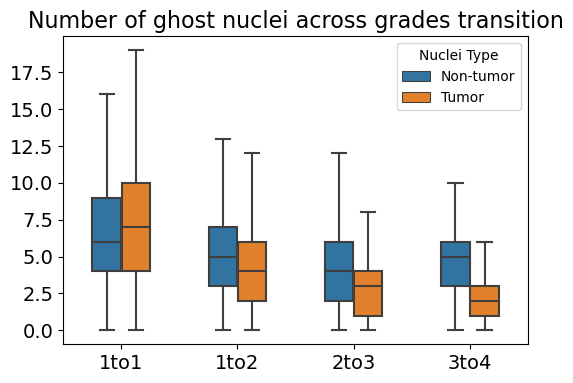

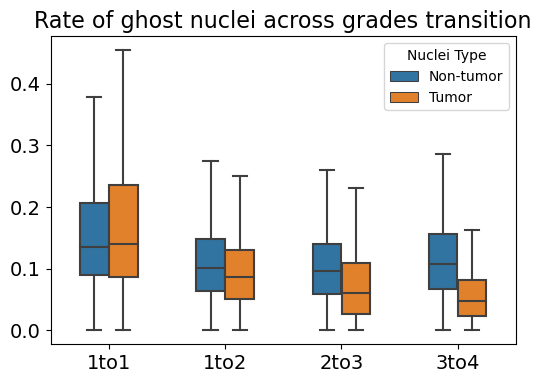

In [17]:
#show number of ghost nuclei in each grade

save_dir = file_paths['synthetic_data']['synthetic_data_grade1to4']
# start_grd = 3
# save_dir = file_paths['synthetic_data']['synthetic_data_grade4to1']
with open(save_dir,'rb') as f:
    observed_data = pickle.load(f)
    
Nuclei_seg = observed_data['full_grade_list_Nuc_seg']
Nuclei_seg_across_patient = observed_data['patient_across_img_Nuc_seg']
print(Nuclei_seg_across_patient.shape)
ghost_nuclei_num_list = {'1to1':[], '1to2':[], '2to3':[], '3to4':[]}
real_nuclei_num_list = [[], [], [], []]
ghost_non_tumor_list = {'1to1':[], '1to2':[], '2to3':[], '3to4':[]}
for sample_grade in range(4):
    if sample_grade == 0:
        mask1_list = Nuclei_seg[:,sample_grade,:,:]
        mask2_list = Nuclei_seg_across_patient
    else:
        mask1_list = Nuclei_seg[:,sample_grade-1,:,:]
        mask2_list = Nuclei_seg[:,sample_grade,:,:]
    for i in range(mask1_list.shape[0]):
        mask1 = mask1_list[i]
        mask2 = mask2_list[i]
        ghost_nuclei_mask = ghost_nuclei_mask_detection(mask1, mask2)
        nObj, labelTest, statsTa, centroids=cv2.connectedComponentsWithStats(\
            np.uint8(ghost_nuclei_mask>0),8,cv2.CV_32S)
        if sample_grade == 0:
            ghost_nuclei_num_list[f'{sample_grade+1}to{sample_grade+1}'].append(nObj-1)
        else:
            ghost_nuclei_num_list[f'{sample_grade}to{sample_grade+1}'].append(nObj-1)
        real_nuclei_mask = np.uint8(Nuclei_seg[i,sample_grade,:,:]>0)
        nObj_real, labelTest, statsTa, centroids=cv2.connectedComponentsWithStats(\
            real_nuclei_mask,8,cv2.CV_32S)
        real_nuclei_num_list[sample_grade].append(nObj_real-1)
        non_tumor_mask = mask1*ghost_nuclei_mask+mask2*ghost_nuclei_mask
        if 1 in np.unique(non_tumor_mask):
            nObj_non_tumor, labelTest, statsTa, centroids=cv2.connectedComponentsWithStats(\
                np.uint8(non_tumor_mask==1),8,cv2.CV_32S)
        else:
            nObj_non_tumor = 1
        if sample_grade == 0:
            ghost_non_tumor_list[f'{sample_grade+1}to{sample_grade+1}'].append(nObj_non_tumor-1)
        else:
            ghost_non_tumor_list[f'{sample_grade}to{sample_grade+1}'].append(nObj_non_tumor-1)

#plot the number of ghost nuclei in each grade
import seaborn as sns
import pandas as pd
grade_name = ['1to1','1to2', '2to3', '3to4']


plt.figure(figsize=(6,4))
ghost_non_tumor_num = []
grade_list = []
nuclei_type_list = []
for grade in grade_name:
    ghost_non_tumor_num += ghost_non_tumor_list[grade]
    grade_list += [grade]*len(ghost_non_tumor_list[grade])
    nuclei_type_list += ['Non-tumor']*len(ghost_non_tumor_list[grade])
for i, grade in enumerate(grade_name):
    ghost_tumor_num = np.array(ghost_nuclei_num_list[grade])-np.array(ghost_non_tumor_list[grade])
    ghost_non_tumor_num += list(ghost_tumor_num)
    grade_list += [grade]*len(ghost_tumor_num)
    nuclei_type_list += ['Tumor']*len(ghost_tumor_num)
df = pd.DataFrame({'Grade': grade_list, 'Number of Non-tumor Nuclei': ghost_non_tumor_num, 'Nuclei Type': nuclei_type_list})   
sns.boxplot(x='Grade', y='Number of Non-tumor Nuclei', hue='Nuclei Type', data=df, showfliers = False, width=0.5)
plt.xlabel('')
plt.ylabel('')
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.title('Number of ghost nuclei across grades transition', fontsize=16)

plt.figure(figsize=(6,4))

ghost_non_tumor_rate = []
grade_list = []
nuclei_type_list = []
for i, grade in enumerate(grade_name):
    ghost_non_tumor_rate += list(np.array(ghost_non_tumor_list[grade])/np.array(real_nuclei_num_list[i]))
    grade_list += [grade]*len(ghost_non_tumor_list[grade])
    nuclei_type_list += ['Non-tumor']*len(ghost_non_tumor_list[grade])
for i, grade in enumerate(grade_name):
    ghost_tumor_rate = list((np.array(ghost_nuclei_num_list[grade])-np.array(ghost_non_tumor_list[grade]))/np.array(real_nuclei_num_list[i]))
    ghost_non_tumor_rate += ghost_tumor_rate
    grade_list += [grade]*len(ghost_tumor_rate)
    nuclei_type_list += ['Tumor']*len(ghost_tumor_rate)
df = pd.DataFrame({'Grade': grade_list, 'Rate of Non-tumor Nuclei': ghost_non_tumor_rate, 'Nuclei Type': nuclei_type_list})
sns.boxplot(x='Grade', y='Rate of Non-tumor Nuclei', hue='Nuclei Type', data=df, showfliers = False, width=0.5)
plt.xlabel('')
plt.ylabel('')
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.title('Rate of ghost nuclei across grades transition', fontsize=16)

# ghost_nuclei_num = []
# grade_list = []
# for grade in grade_name:
#     ghost_nuclei_num += ghost_nuclei_num_list[grade]
#     grade_list += [grade]*len(ghost_nuclei_num_list[grade])
# df = pd.DataFrame({'Grade': grade_list, 'Number of Ghost Nuclei': ghost_nuclei_num})
# plt.figure(figsize=(6,4))
# sns.boxplot(x='Grade', y='Number of Ghost Nuclei', data=df, showfliers = False, width=0.5)
# plt.xlabel('')
# plt.ylabel('')
# plt.xticks(fontsize=14)
# plt.yticks(fontsize=14)
# plt.title('Number of Ghost Nuclei across Grades', fontsize=16)

# #plot number of rate of ghost nuclei to real nuclei in each grade
# plt.figure(figsize=(6,4))
# ghost_nuclei_rate = []
# grade_list = []
# for i, grade in enumerate(grade_name):
#     ghost_nuclei_rate += list(np.array(ghost_nuclei_num_list[grade])/np.array(real_nuclei_num_list[i]))
#     grade_list += [grade]*len(ghost_nuclei_num_list[grade])
# df = pd.DataFrame({'Grade': grade_list, 'Rate of Ghost Nuclei': ghost_nuclei_rate})
# sns.boxplot(x='Grade', y='Rate of Ghost Nuclei', data=df, showfliers = False, width=0.5)
# plt.xlabel('')
# plt.ylabel('')
# plt.xticks(fontsize=14)
# plt.yticks(fontsize=14)
# plt.title('Rate of Ghost Nuclei across Grades transition', fontsize=16)


        